# NIT6160 Data Warehousing and Mining — Project
## Health Dataset Analysis and Prediction: Cardiovascular Disease

**Student:** Sunil Sapkota | **Student ID:** s8206069

**Dataset:** Cardiovascular Disease dataset (Kaggle, S. Ulianova), `cardio_train.csv` — 70,000 patient records, 11 features, binary target `cardio`.

**Scope:** the task classifies *recorded* presence of cardiovascular disease from a single examination. It does not predict future events or give a validated clinical risk score.

**Notebook structure**
0. Setup – configuration, reproducibility and helper functions (`load_data`, `quality_flags`, `clean`, `metrics`)
1. Task 1 – Dataset selection and description
2. Task 2 – Research questions
3. Task 3 – Data exploration (structure, missing data, descriptive statistics, central tendency and dispersion, data quality audit)
4. Data pre-processing (documented exclusion rules, feature engineering)
5. Task 4 – Data visualisation
6. Task 5 – Machine learning models, hyperparameter tuning and evaluation
7. Task 6 – Interpretation and conclusion

**Submission:** this notebook includes all analysis code and embedded outputs. It uses a matching local CSV when available; otherwise it downloads a public, immutable GitHub copy of the cited Kaggle file and verifies its SHA-256. No separate CSV, modules, figures or JSON files need to be submitted. Internet access is needed to rerun without the CSV. Python packages are still required: numpy, pandas, scipy, scikit-learn, matplotlib and seaborn. The CSV was retrieved from the cited Kaggle dataset; commercial reuse terms still need confirmation.

**To reproduce:** *Kernel → Restart & Run All*. The notebook finds `cardio_train.csv` in the current folder or any parent folder, uses a fixed seed and writes figures to `figures/` and metrics to `reports/notebook_results.json`.


## Task 1 – Dataset Selection

The Cardiovascular Disease dataset contains examination data for 70,000 patients. Every record contains three types of input features:

| Type | Feature | Column | Values |
|---|---|---|---|
| Objective (demographic) | Age | `age` | int, **days** |
| Objective (demographic) | Gender | `gender` | 1 = female, 2 = male |
| Objective | Height | `height` | cm |
| Objective | Weight | `weight` | kg |
| Examination (clinical) | Systolic blood pressure | `ap_hi` | mmHg |
| Examination (clinical) | Diastolic blood pressure | `ap_lo` | mmHg |
| Examination (clinical) | Cholesterol | `cholesterol` | 1 normal, 2 above normal, 3 well above normal |
| Examination (clinical) | Glucose | `gluc` | 1 normal, 2 above normal, 3 well above normal |
| Subjective (lifestyle) | Smoking | `smoke` | 0/1 |
| Subjective (lifestyle) | Alcohol intake | `alco` | 0/1 |
| Subjective (lifestyle) | Physical activity | `active` | 0/1 |
| **Target** | Presence of cardiovascular disease | `cardio` | 0/1 |

It covers the variable groups suggested by the brief (demographics, clinical measurements, lifestyle factors and a health outcome) and is large enough for robust cross-validation. Cholesterol and glucose are ordinal categories, not laboratory concentrations. The country of origin, recruitment design and diagnostic definition are not documented.


## Task 2 – Research Questions

- **RQ1.** What are the most significant factors associated with the presence of cardiovascular disease (CVD)?
- **RQ2.** Is there a relationship between demographic factors (age, gender) and CVD?
- **RQ3.** How do lifestyle factors (smoking, alcohol intake, physical activity) relate to CVD?
- **RQ4.** Which variables contribute most to the prediction accuracy of machine learning models?
- **RQ5.** Can machine learning models (Logistic Regression, Random Forest, Neural Network) effectively predict CVD, and which offers the best accuracy–interpretability trade-off?

The written report summarises three journal studies: Bhatt et al. (2023), Kahraman (2025) and Sadr et al. (2024). They motivate comparing linear and nonlinear models and reporting preprocessing differences, rather than comparing headline accuracy as though cohorts were identical.


## Setup
Imports, configuration and the helper functions used throughout the notebook. All constants (paths, seed, plausibility limits) are defined once here, so a change in one place applies everywhere.


In [1]:
import hashlib
import io
import json
import os
import platform
from pathlib import Path
from urllib.request import urlopen

# Use half the CPU cores for searches: fast on a desktop, still responsive on a laptop.
# scikit-learn runs on the CPU only; a GPU is not used by any model in this notebook.
N_JOBS = max(1, (os.cpu_count() or 2) // 2)

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import sklearn
from scipy import stats
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedGroupKFold,
    cross_validate,
)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", context="notebook")

SEED = 42 # fixes randomness in the notebook for reproducibility
DATA_FILE = "cardio_train.csv"
# Works whether the notebook is opened from the project root or a sub-folder
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / DATA_FILE).exists()), Path.cwd())
FIG_DIR = ROOT / "figures"
REPORT_DIR = ROOT / "reports"
FIG_DIR.mkdir(exist_ok=True)
REPORT_DIR.mkdir(exist_ok=True)

DATA_URL = "https://raw.githubusercontent.com/sunil-9/data-warehouse/03014c799bb1db1167acc07a85b186ecff78e4f2/cardio_train.csv"
DATA_SHA256 = "21a705d23381b0dfd6a6416da701b490744f1fc3b47e9ff3db3968c420ffa10c"

RAW_FEATURES = ["age", "gender", "height", "weight", "ap_hi", "ap_lo", "cholesterol", "gluc", "smoke", "alco", "active"]
TARGET = "cardio"
# Prespecified analysis filters (inclusive), not validated clinical impossibility thresholds.
LIMITS = {"ap_hi": (80, 250), "ap_lo": (40, 160), "height": (120, 220), "weight": (30, 200), "bmi": (10, 70)}

VERSIONS = {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
            "scikit-learn": sklearn.__version__, "scipy": scipy.__version__,
            "matplotlib": matplotlib.__version__, "seaborn": sns.__version__}
print("Sunil Sapkota | s8206069 | NIT6160")
print("Project root:", ROOT)
print(" | ".join(f"{k} {v}" for k, v in VERSIONS.items()))


Sunil Sapkota | s8206069 | NIT6160
Project root: /home/sunil/opt/data warehouse/project
python 3.14.7 | pandas 3.0.6 | numpy 2.5.3 | scikit-learn 1.9.1 | scipy 1.18.1 | matplotlib 3.11.2 | seaborn 0.13.2


In [2]:
def save(name):
    """Save the current figure to figures/ and show it."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def load_data(path=None):
    """Load the semicolon-separated file and validate schema, target and ids before any analysis."""
    source = Path(path) if path else ROOT / DATA_FILE
    if source.exists():
        raw = source.read_bytes()
    else:
        # Public, immutable snapshot of the cited Kaggle file. No credentials needed.
        try:
            with urlopen(DATA_URL, timeout=60) as response:
                raw = response.read()
        except Exception as exc:
            raise RuntimeError("Data download failed. Connect to the internet or place the cited cardio_train.csv beside this notebook.") from exc
    if hashlib.sha256(raw).hexdigest() != DATA_SHA256:
        raise ValueError("Dataset differs from the reviewed file; audit it before using these results")
    df = pd.read_csv(io.BytesIO(raw), sep=";")
    expected = {"id", TARGET, *RAW_FEATURES}
    if set(df.columns) != expected:
        raise ValueError(f"Unexpected schema: {sorted(df.columns)}")
    non_numeric = [c for c in RAW_FEATURES if not pd.api.types.is_numeric_dtype(df[c])]
    if non_numeric:
        raise ValueError(f"Non-numeric predictors (check parsing / separator): {non_numeric}")
    if df[TARGET].isna().any() or not set(df[TARGET].unique()) <= {0, 1}:
        raise ValueError("Target must contain only 0 and 1")
    if df["id"].duplicated().any():
        raise ValueError("Duplicate record identifiers found")
    return df


BP_RULES = ["nonpositive_blood_pressure", "systolic_outside_80_250", "diastolic_outside_40_160", "diastolic_not_below_systolic"]
BODY_RULES = ["height_outside_120_220", "weight_outside_30_200", "bmi_outside_10_70"]
CODE_RULES = ["invalid_gender_code", "invalid_cholesterol_or_glucose_code", "invalid_binary_predictor"]

def quality_flags(df):
    """One boolean column per data-quality rule; True means the row breaks that rule."""
    bmi = df.weight / (df.height / 100) ** 2
    return pd.DataFrame({
        "nonpositive_blood_pressure": (df.ap_hi <= 0) | (df.ap_lo <= 0),
        "systolic_outside_80_250": ~df.ap_hi.between(*LIMITS["ap_hi"]),
        "diastolic_outside_40_160": ~df.ap_lo.between(*LIMITS["ap_lo"]),
        # Pulse pressure (ap_hi - ap_lo) must be positive: systolic equal to diastolic is physiologically impossible.
        "diastolic_not_below_systolic": df.ap_lo >= df.ap_hi,
        "height_outside_120_220": ~df.height.between(*LIMITS["height"]),
        "weight_outside_30_200": ~df.weight.between(*LIMITS["weight"]),
        "bmi_outside_10_70": ~bmi.between(*LIMITS["bmi"]),
        "invalid_gender_code": ~df.gender.isin([1, 2]),
        "invalid_cholesterol_or_glucose_code": ~df.cholesterol.isin([1, 2, 3]) | ~df.gluc.isin([1, 2, 3]),
        "invalid_binary_predictor": ~df[["smoke", "alco", "active"]].isin([0, 1]).all(axis=1),
    }, index=df.index)


def clean(df):
    """Apply the documented exclusion rules and feature engineering. Returns (clean_df, exclusion_log)."""
    log = {"original rows": len(df)}
    out = df.drop(columns="id").drop_duplicates()
    log["exact duplicate records removed"] = log["original rows"] - len(out)

    flags = quality_flags(out)
    bad_bp = flags[BP_RULES].any(axis=1)
    bad_body = flags[BODY_RULES].any(axis=1) & ~bad_bp
    bad_code = flags[CODE_RULES].any(axis=1) & ~bad_bp & ~bad_body
    log["implausible blood pressure removed"] = int(bad_bp.sum())
    log["implausible height/weight/BMI removed"] = int(bad_body.sum())
    log["invalid category codes removed"] = int(bad_code.sum())
    out = out[~flags.any(axis=1)].copy()

    out["age_years"] = (out.age / 365.25).round(1)
    out["bmi"] = (out.weight / (out.height / 100) ** 2).round(2)
    out["pulse_pressure"] = out.ap_hi - out.ap_lo  # used in EDA only; not a model input (exactly ap_hi - ap_lo)
    out["male"] = (out.gender == 2).astype(int)
    out = out.drop(columns=["age", "gender"]).reset_index(drop=True)
    # Group the actual model inputs AFTER rounding/engineering. Raw-profile groups
    # are insufficient: rounding age makes additional distinct raw rows identical.
    model_columns = [c for c in out.columns if c != TARGET]
    out["profile_id"] = pd.util.hash_pandas_object(out[model_columns], index=False).values

    # Post-conditions: the rules really hold on the output
    for col, (lo, hi) in LIMITS.items():
        assert out[col].between(lo, hi).all(), col
    assert (out.ap_hi > out.ap_lo).all() and not out.isna().any().any()

    log["final rows"] = len(out)
    log["percent retained"] = round(len(out) / log["original rows"] * 100, 2)
    return out, log


def metrics(y_true, proba, threshold=0.5):
    """Classification metrics at a fixed threshold plus threshold-free ranking/calibration metrics."""
    pred = (proba >= threshold).astype(int)
    return {"Accuracy": accuracy_score(y_true, pred), "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred, zero_division=0), "F1": f1_score(y_true, pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_true, proba), "Avg precision": average_precision_score(y_true, proba),
            "Brier": brier_score_loss(y_true, proba)}

## Task 3 – Data Exploration
### 3.1 Load and examine the dataset


In [3]:
df_raw = load_data()
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (70000, 13)


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [4]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


### 3.2 Missing data and duplicates


In [5]:
missing = pd.DataFrame({"missing": df_raw.isna().sum(), "percent": (df_raw.isna().mean() * 100).round(2)})
print(missing.T)
profiles = df_raw.groupby(RAW_FEATURES)[TARGET].nunique()
print("\nDuplicate records (ignoring id):", df_raw.drop(columns="id").duplicated().sum())
print("Duplicate predictor profiles:", df_raw.duplicated(RAW_FEATURES).sum())
print("Profiles with conflicting targets (same inputs, different label):", (profiles > 1).sum())

          id  age  gender  height  weight  ap_hi  ap_lo  cholesterol  gluc  smoke  alco  active  cardio
missing  0.0  0.0     0.0     0.0     0.0    0.0    0.0          0.0   0.0    0.0   0.0     0.0     0.0
percent  0.0  0.0     0.0     0.0     0.0    0.0    0.0          0.0   0.0    0.0   0.0     0.0     0.0

Duplicate records (ignoring id): 24
Duplicate predictor profiles: 41
Profiles with conflicting targets (same inputs, different label): 17


There are **no missing (NaN) values**. A few predictor profiles appear more than once, and some of them carry *different* labels. These are handled in the split (Task 5b) so that identical inputs never leak between training and test data. The summary statistics below also show that the data contains impossible values, which are a hidden data quality problem.


### 3.3 Descriptive statistics


In [6]:
df = df_raw.drop(columns="id").copy()
df["age_years"] = (df["age"] / 365.25).round(1)
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,70000.0,19468.87,2467.25,10798.0,17664.0,19703.0,21327.0,23713.0
gender,70000.0,1.35,0.48,1.0,1.0,1.0,2.0,2.0
height,70000.0,164.36,8.21,55.0,159.0,165.0,170.0,250.0
weight,70000.0,74.21,14.40,10.0,65.0,72.0,82.0,200.0
ap_hi,70000.0,128.82,154.01,-150.0,120.0,120.0,140.0,16020.0
ap_lo,70000.0,96.63,188.47,-70.0,80.0,80.0,90.0,11000.0
cholesterol,70000.0,1.37,0.68,1.0,1.0,1.0,2.0,3.0
gluc,70000.0,1.23,0.57,1.0,1.0,1.0,1.0,3.0
smoke,70000.0,0.09,0.28,0.0,0.0,0.0,0.0,1.0
alco,70000.0,0.05,0.23,0.0,0.0,0.0,0.0,1.0


### 3.4 Central tendency and dispersion


In [7]:
num_cols = ["age_years", "height", "weight", "ap_hi", "ap_lo"]
ct = pd.DataFrame({
    "mean": df[num_cols].mean(),
    "median": df[num_cols].median(),
    "mode": df[num_cols].mode().iloc[0],
    "variance": df[num_cols].var(),
    "std": df[num_cols].std(),
    "min": df[num_cols].min(),
    "max": df[num_cols].max(),
    "IQR": df[num_cols].quantile(0.75) - df[num_cols].quantile(0.25),
    "skewness": df[num_cols].skew(),
    "kurtosis": df[num_cols].kurt(),
}).round(2)
ct

,mean,median,mode,variance,std,min,max,IQR,skewness,kurtosis
age_years,53.30,53.9,56.0,45.63,6.76,29.6,64.9,10.0,-0.31,-0.82
height,164.36,165.0,165.0,67.41,8.21,55.0,250.0,11.0,-0.64,7.94
weight,74.21,72.0,65.0,207.24,14.40,10.0,200.0,17.0,1.01,2.59
ap_hi,128.82,120.0,120.0,23719.52,154.01,-150.0,16020.0,20.0,85.30,7580.07
ap_lo,96.63,80.0,80.0,35521.89,188.47,-70.0,11000.0,10.0,32.11,1425.91


In [8]:
cat_cols = ["gender", "cholesterol", "gluc", "smoke", "alco", "active", "cardio"]
cat_summary = pd.concat({c: df[c].value_counts().sort_index().to_frame("count")
                         .assign(percent=lambda t: (t["count"] / len(df) * 100).round(1)) for c in cat_cols})
cat_summary

count  percent
gender      1  45530     65.0
            2  24470     35.0
cholesterol 1  52385     74.8
            2   9549     13.6
            3   8066     11.5
gluc        1  59479     85.0
            2   5190      7.4
            3   5331      7.6
smoke       0  63831     91.2
            1   6169      8.8
alco        0  66236     94.6
            1   3764      5.4
active      0  13739     19.6
            1  56261     80.4
cardio      0  35021     50.0
            1  34979     50.0

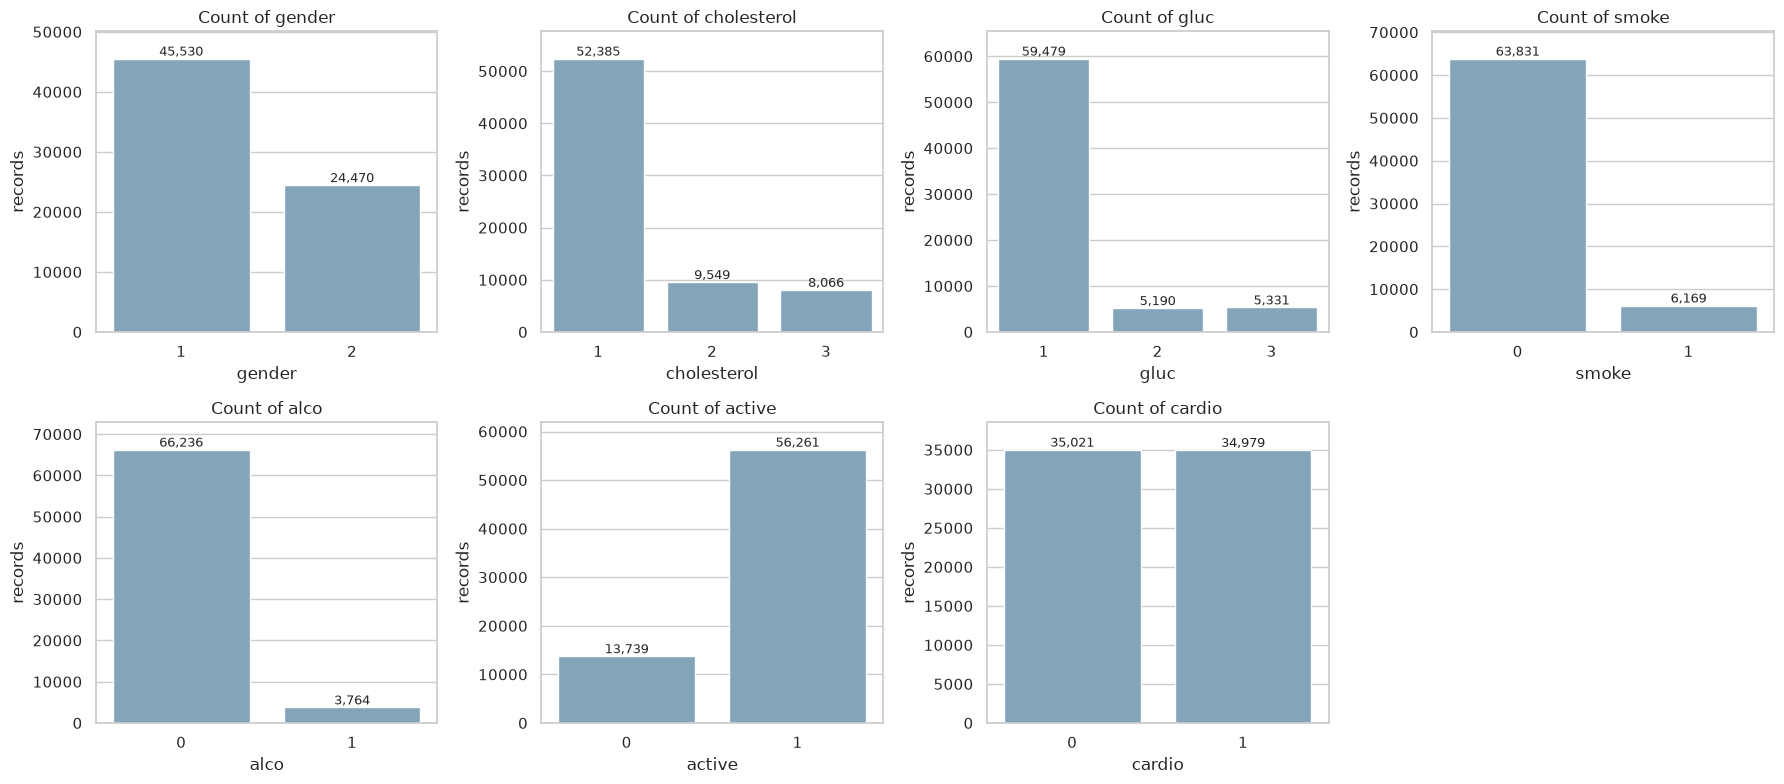

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), cat_cols):
    sns.countplot(data=df, x=c, ax=ax, color="#7aa6c2")
    for container in ax.containers:
        ax.bar_label(container, fmt="{:,.0f}", fontsize=9)
    ax.set_title(f"Count of {c}"); ax.set_ylabel("records"); ax.margins(y=0.1)
axes.ravel()[-1].set_visible(False)
save("00_countplots_categorical")

**Observations**
- The target is **balanced** (≈50% / 50%), so accuracy is a meaningful metric and resampling is not needed.
- Women (gender = 1) make up about 65% of records. Mean height does not establish the meaning of a gender code; verify the documented mapping before interpreting it.
- `ap_hi` and `ap_lo` have extreme variance (std > 150 mmHg) and kurtosis, with maxima of 16,020 and 11,000 mmHg and negative minima. These are clearly data entry errors.
- `height` (55–250 cm) and `weight` (10–200 kg) also contain implausible values.


### 3.5 Data quality audit


In [10]:
flags = quality_flags(df_raw)
audit = flags.sum().to_frame("rows")
audit["percent"] = (audit.rows / len(df_raw) * 100).round(2)
print(audit)
print("\nRows breaking at least one rule:", flags.any(axis=1).sum())

def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

print("\nFor comparison, IQR (1.5×) outlier counts:")
print(pd.Series({c: iqr_outliers(df[c]) for c in num_cols}))

                                     rows  percent
nonpositive_blood_pressure             29     0.04
systolic_outside_80_250               247     0.35
diastolic_outside_40_160             1025     1.46
diastolic_not_below_systolic         1236     1.77
height_outside_120_220                 53     0.08
weight_outside_30_200                   7     0.01
bmi_outside_10_70                      42     0.06
invalid_gender_code                     0     0.00
invalid_cholesterol_or_glucose_code     0     0.00
invalid_binary_predictor                0     0.00

Rows breaking at least one rule: 1395

For comparison, IQR (1.5×) outlier counts:
age_years       4
height        519
weight       1819
ap_hi        1435
ap_lo        4632
dtype: int64


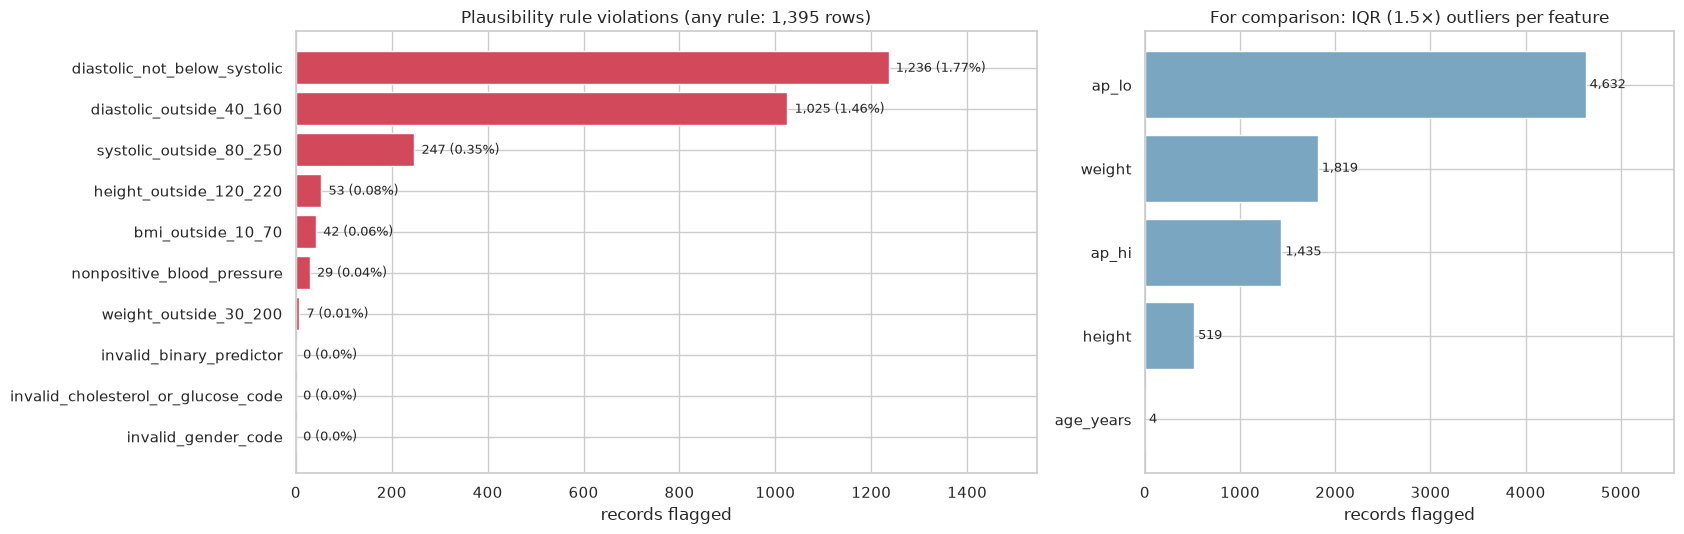

In [11]:
iqr_counts = pd.Series({c: iqr_outliers(df[c]) for c in num_cols}).sort_values()
rules = audit.sort_values("rows")
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1.4, 1]})

colors = ["#d1495b" if r > 0 else "#bbbbbb" for r in rules["rows"]]
axes[0].barh(rules.index, rules["rows"], color=colors)
for i, (r, pct) in enumerate(zip(rules["rows"], rules["percent"])):
    axes[0].text(r + 15, i, f"{r:,} ({pct}%)", va="center", fontsize=9)
axes[0].set(xlabel="records flagged", title=f"Plausibility rule violations (any rule: {flags.any(axis=1).sum():,} rows)")
axes[0].set_xlim(0, rules["rows"].max() * 1.25)

axes[1].barh(iqr_counts.index, iqr_counts.values, color="#7aa6c2")
for i, v in enumerate(iqr_counts.values):
    axes[1].text(v + 40, i, f"{v:,}", va="center", fontsize=9)
axes[1].set(xlabel="records flagged", title="For comparison: IQR (1.5×) outliers per feature")
axes[1].set_xlim(0, iqr_counts.max() * 1.2)
save("01a_data_quality_audit")

Most rule violations involve blood pressure: diastolic at or above systolic and diastolic outside 40–160 mmHg together account for most of the flagged rows, while height and weight problems are rare and no category codes are invalid. The IQR rule would flag far more records (over 4,600 for `ap_lo` alone), many of them plausible clinical values, which is why fixed plausibility limits are used instead of IQR trimming.

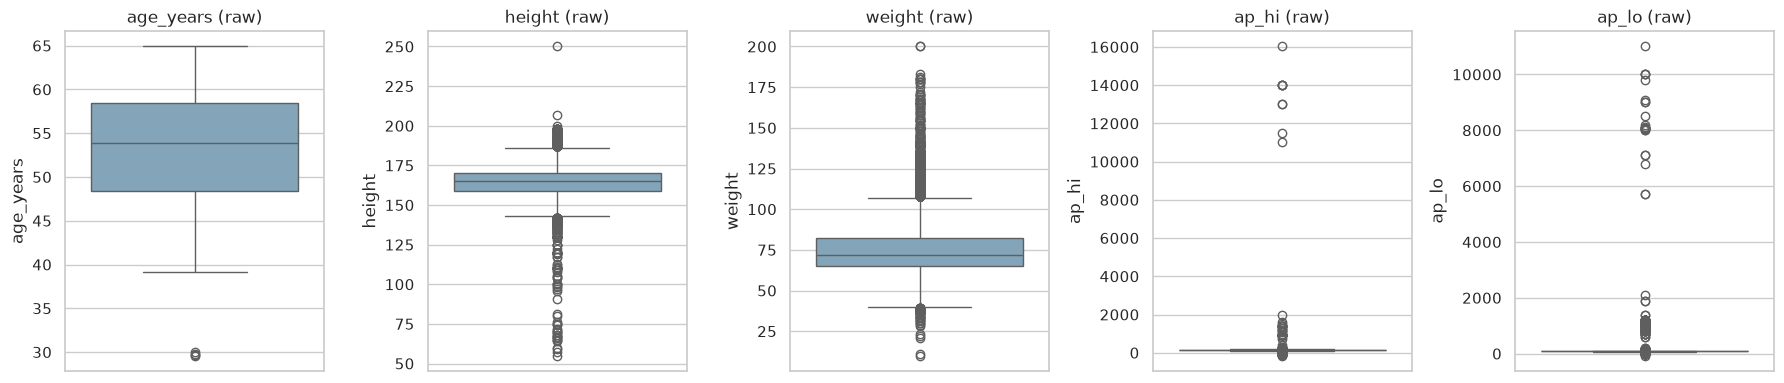

In [12]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(y=df[c], ax=ax, color="#7aa6c2")
    ax.set_title(f"{c} (raw)")
save("01_boxplots_raw")

## Data Pre-processing

The fixed limits in `LIMITS` are **analysis inclusion filters**, not proof that every excluded measurement is physiologically impossible. Some extreme measurements can be genuine. Their clinical justification and a sensitivity analysis remain limitations.

1. Remove exact duplicate records excluding the record ID; retain conflicting-label profiles together.
2. Apply the prespecified blood-pressure and body-measurement filters; record exclusions. Systolic must be strictly above diastolic: a pulse pressure of zero or less is physiologically impossible and indicates a recording error.
3. Engineer age in years, BMI, pulse pressure and a recoded gender indicator. Pulse pressure (systolic − diastolic) is a recognised marker of arterial stiffness and is used in the exploratory analysis, but it is **not a model input**: it equals `ap_hi − ap_lo` exactly, so it adds no information beyond the two blood-pressure readings.
4. Group **the final engineered model inputs**, including rounded age/BMI, before splitting. This avoids identical model inputs crossing partitions.
5. Fit scaling within each training fold using a Pipeline. No scaler sees held-out test data.

This grouped split prevents identical-input leakage but cannot prove patient independence because patient identity is not established by the record ID. Filtering defines the study cohort and may introduce selection bias. The retained-data results cannot establish performance for excluded patients.


In [13]:
clean_df, exclusion_log = clean(df_raw)
print(pd.Series(exclusion_log).to_string())
print("\nTarget balance after cleaning:", clean_df[TARGET].value_counts(normalize=True).round(3).to_dict())
clean_df.drop(columns="profile_id").describe().T.round(2)

original rows                            70000.00
exact duplicate records removed             24.00
implausible blood pressure removed        1336.00
implausible height/weight/BMI removed       59.00
invalid category codes removed               0.00
final rows                               68581.00
percent retained                            97.97

Target balance after cleaning: {0: 0.505, 1: 0.495}


,count,mean,std,min,25%,50%,75%,max
height,68581.0,164.42,7.91,120.00,159.00,165.00,170.00,207.00
weight,68581.0,74.11,14.29,30.00,65.00,72.00,82.00,200.00
ap_hi,68581.0,126.68,16.68,80.00,120.00,120.00,140.00,240.00
ap_lo,68581.0,81.31,9.43,40.00,80.00,80.00,90.00,160.00
cholesterol,68581.0,1.36,0.68,1.00,1.00,1.00,2.00,3.00
gluc,68581.0,1.23,0.57,1.00,1.00,1.00,1.00,3.00
smoke,68581.0,0.09,0.28,0.00,0.00,0.00,0.00,1.00
alco,68581.0,0.05,0.22,0.00,0.00,0.00,0.00,1.00
active,68581.0,0.80,0.40,0.00,1.00,1.00,1.00,1.00
cardio,68581.0,0.49,0.50,0.00,0.00,0.00,1.00,1.00


### Exclusion waterfall
Each red bar is the number of rows removed at one cleaning step, applied in order from the original file to the final cohort. The y-axis does not start at zero, so that removals of a few dozen rows stay visible next to the 70,000-row total.

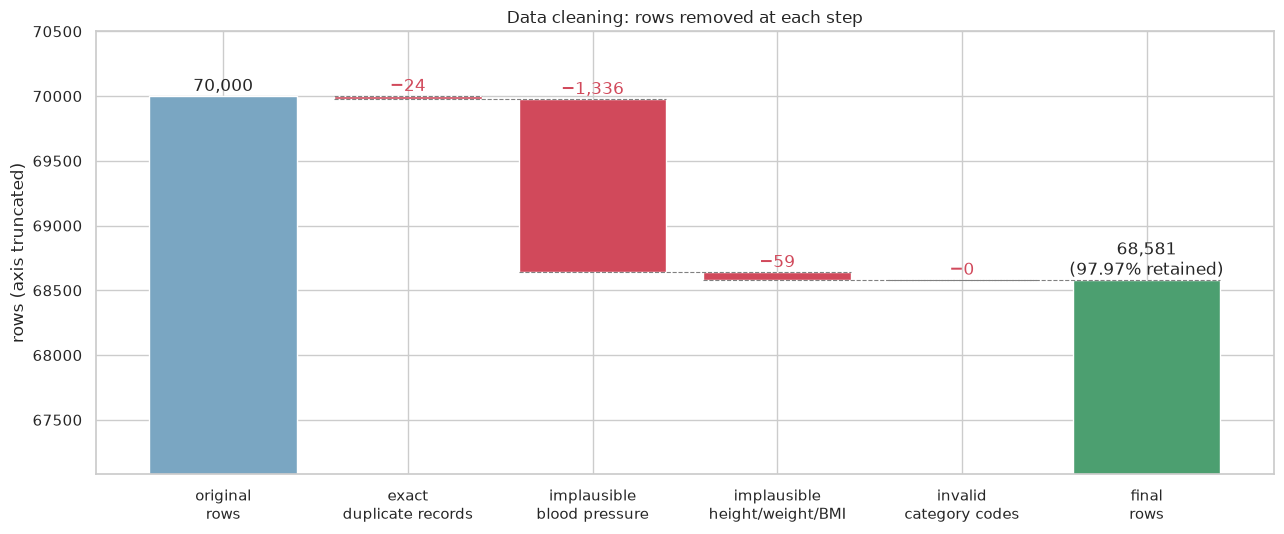

In [14]:
steps = {k.replace(" removed", ""): int(v) for k, v in exclusion_log.items() if k.endswith("removed")}
start, final = int(exclusion_log["original rows"]), int(exclusion_log["final rows"])
labels = ["original rows", *steps, "final rows"]
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.bar(0, start, color="#7aa6c2")
ax.text(0, start + 40, f"{start:,}", ha="center")
level = start
for i, (step, n) in enumerate(steps.items(), start=1):
    ax.bar(i, -n if n else 0, bottom=level, color="#d1495b")
    ax.text(i, level + 40, f"−{n:,}", ha="center", color="#d1495b")
    ax.plot([i - 0.4, i + 1.4], [level - n] * 2, color="grey", lw=0.8, ls="--")
    level -= n
ax.plot([0.6, 1.4], [start] * 2, color="grey", lw=0.8, ls="--")
ax.bar(len(labels) - 1, final, color="#4c9f70")
ax.text(len(labels) - 1, final + 40, f"{final:,}\n({exclusion_log['percent retained']}% retained)", ha="center")
ax.set_xticks(range(len(labels)), [l.replace(" ", "\n", 1) for l in labels])
ax.set_ylim(final - 1500, start + 500)
ax.set(ylabel="rows (axis truncated)", title="Data cleaning: rows removed at each step")
assert level == final, "exclusion steps do not reconcile with the final row count"
save("01c_exclusion_waterfall")

### Box plots before and after cleaning
The same five numerical features: the top row is the raw data and the bottom row is the cleaned data. Each pair shares its title, but the y-axes differ because the raw ranges are dominated by entry errors.

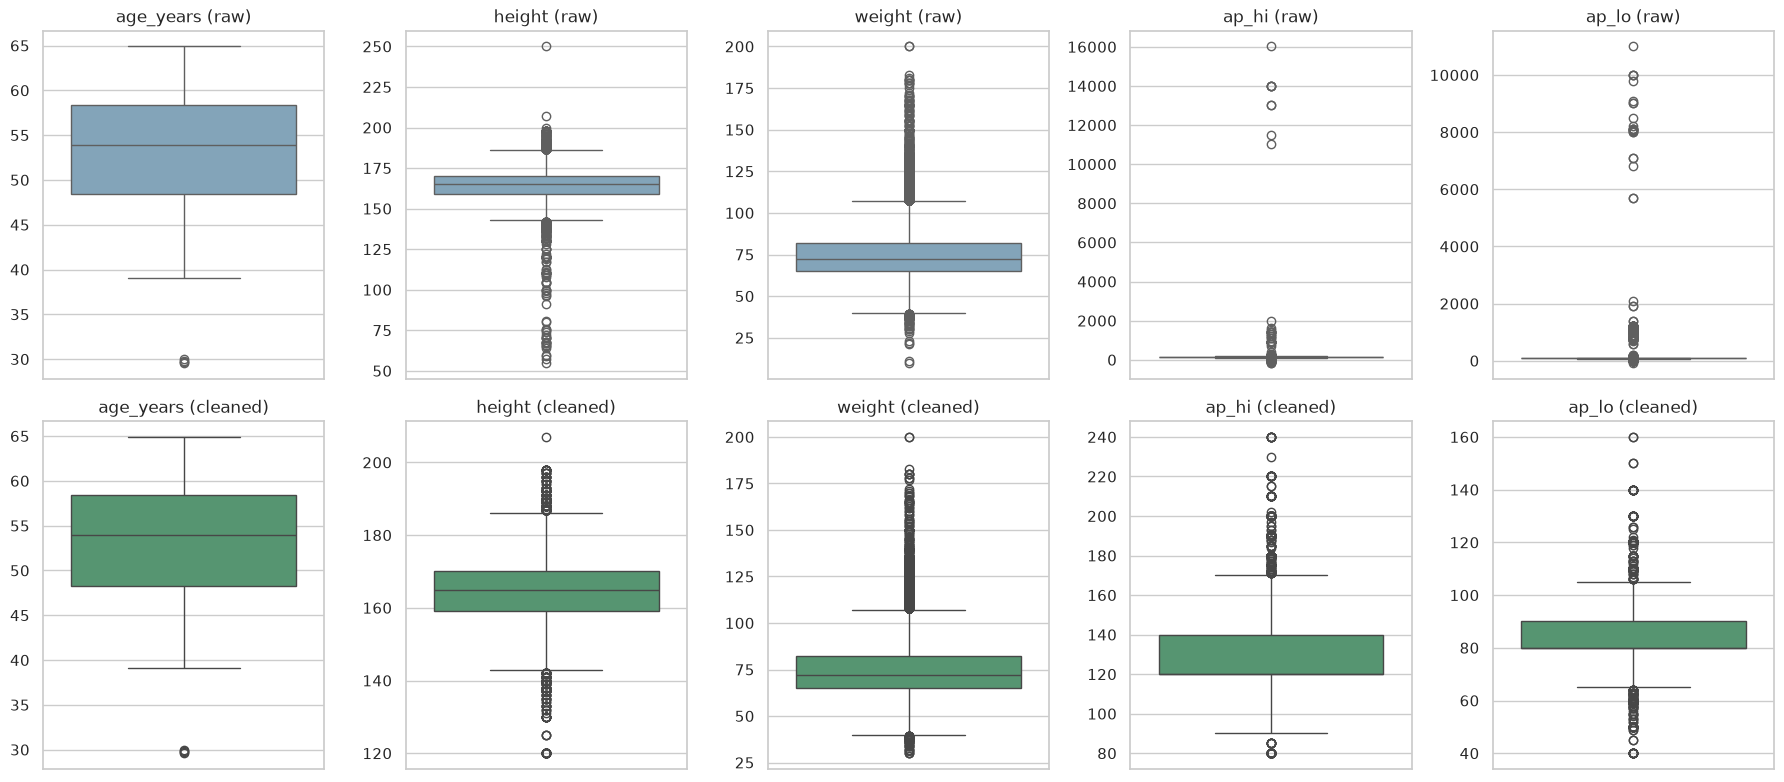

In [15]:
fig, axes = plt.subplots(2, len(num_cols), figsize=(18, 8))
for j, c in enumerate(num_cols):
    sns.boxplot(y=df[c], ax=axes[0, j], color="#7aa6c2")
    sns.boxplot(y=clean_df[c], ax=axes[1, j], color="#4c9f70")
    axes[0, j].set_title(f"{c} (raw)"); axes[1, j].set_title(f"{c} (cleaned)")
    axes[0, j].set_ylabel(""); axes[1, j].set_ylabel("")
save("01b_boxplots_before_after")

After cleaning, the blood-pressure boxes become readable (the raw axes are stretched to thousands of mmHg by a handful of errors), heights below 120 cm and weights below 30 kg are gone. The points that remain beyond the whiskers are plausible but unusual values, which the filters intentionally keep.

## Task 4 – Data Visualisation
### 4.1 Distributions (histograms)


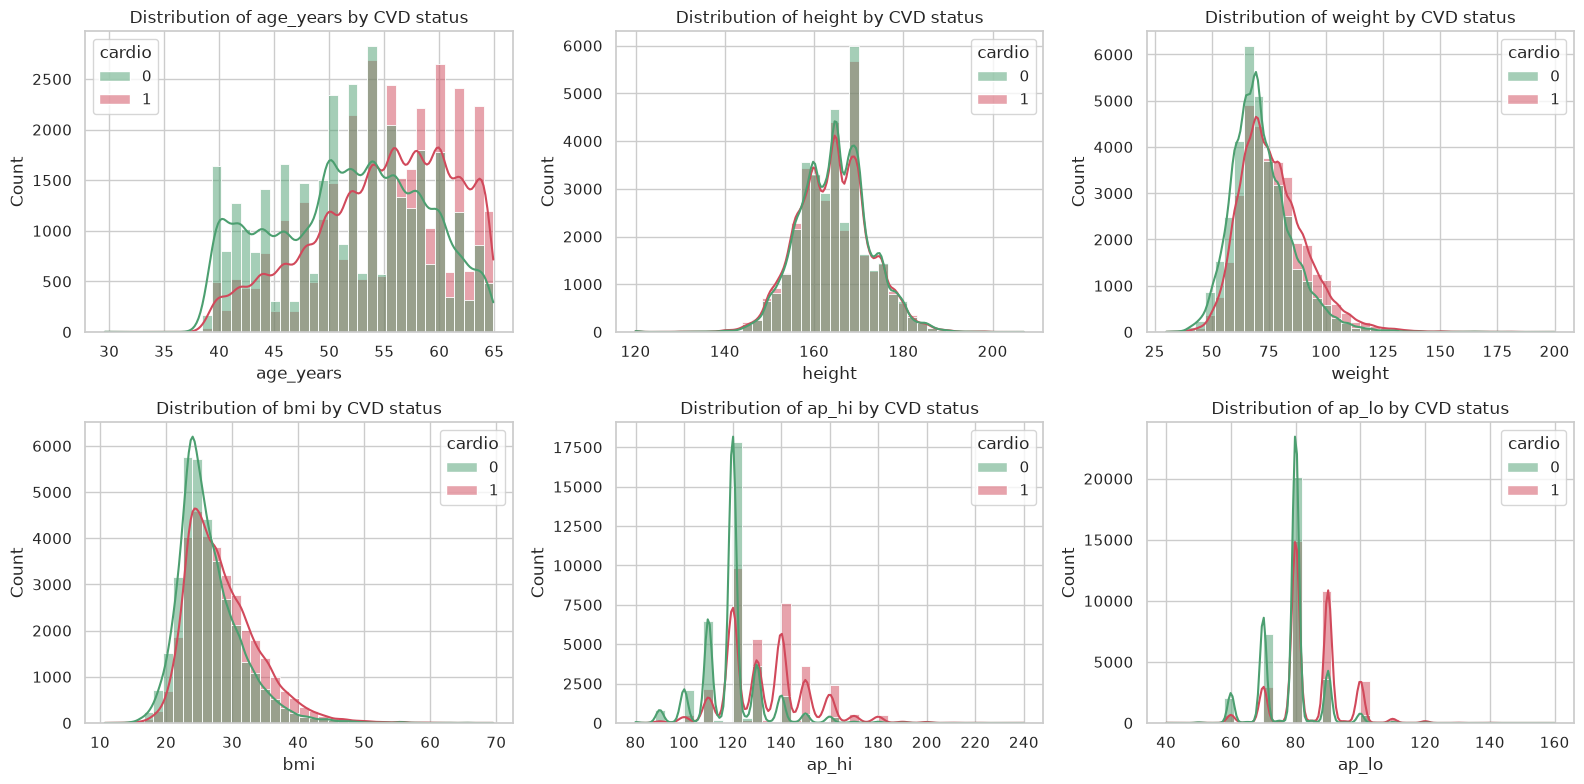

In [16]:
PALETTE = {0: "#4c9f70", 1: "#d1495b"}
plot_num = ["age_years", "height", "weight", "bmi", "ap_hi", "ap_lo"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), plot_num):
    sns.histplot(data=clean_df, x=c, hue=TARGET, bins=40, kde=True, ax=ax, palette=PALETTE, alpha=0.5)
    ax.set_title(f"Distribution of {c} by CVD status")
save("02_histograms")

### 4.2 Box plots by target (cleaned data)


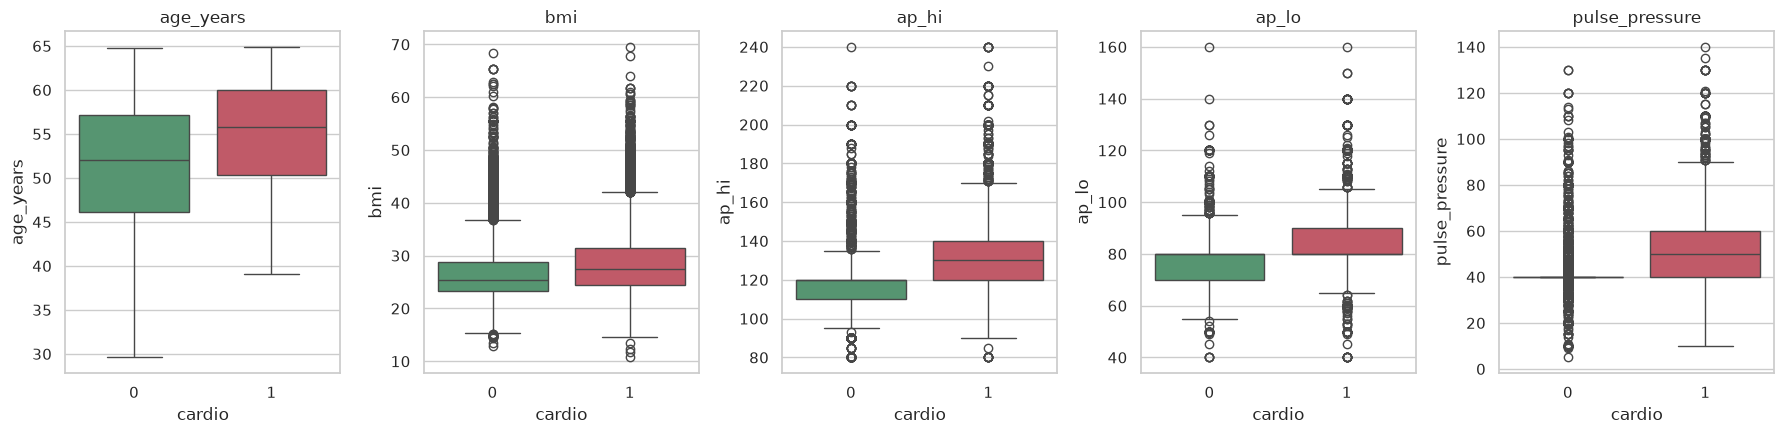

In [17]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4.5))
for ax, c in zip(axes, ["age_years", "bmi", "ap_hi", "ap_lo", "pulse_pressure"]):
    sns.boxplot(data=clean_df, x=TARGET, y=c, hue=TARGET, ax=ax, palette=list(PALETTE.values()), legend=False)
    ax.set_title(c)
save("03_boxplots_by_target")

### 4.3 Categorical and lifestyle factors vs CVD prevalence


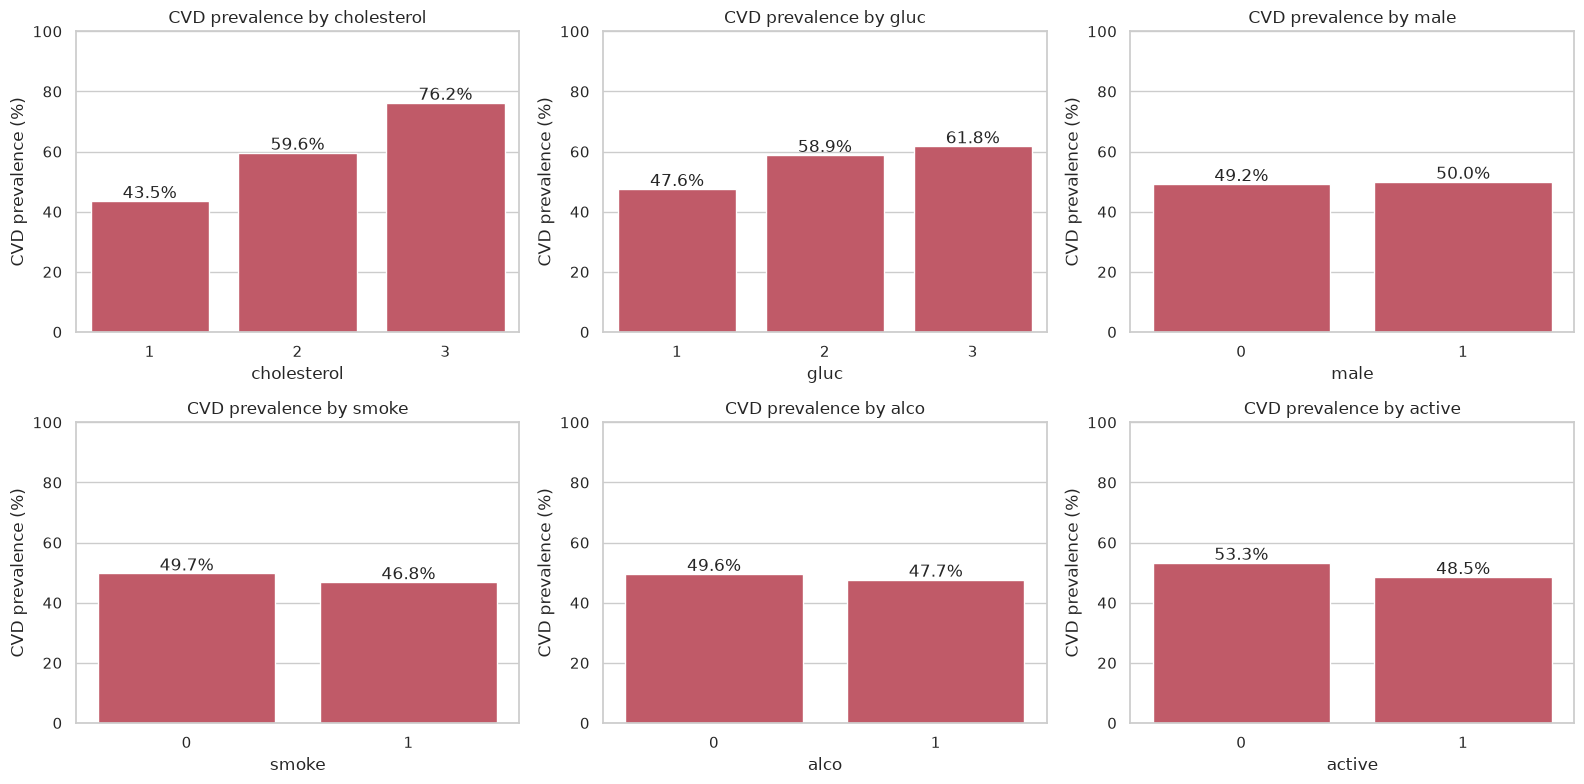

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), ["cholesterol", "gluc", "male", "smoke", "alco", "active"]):
    rate = clean_df.groupby(c)[TARGET].mean() * 100
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, color="#d1495b")
    for i, v in enumerate(rate.values):
        ax.text(i, v + 1, f"{v:.1f}%", ha="center")
    ax.set_ylim(0, 100); ax.set_ylabel("CVD prevalence (%)"); ax.set_title(f"CVD prevalence by {c}")
save("04_prevalence_categorical")

### 4.4 Trend: CVD prevalence by age (line graph)


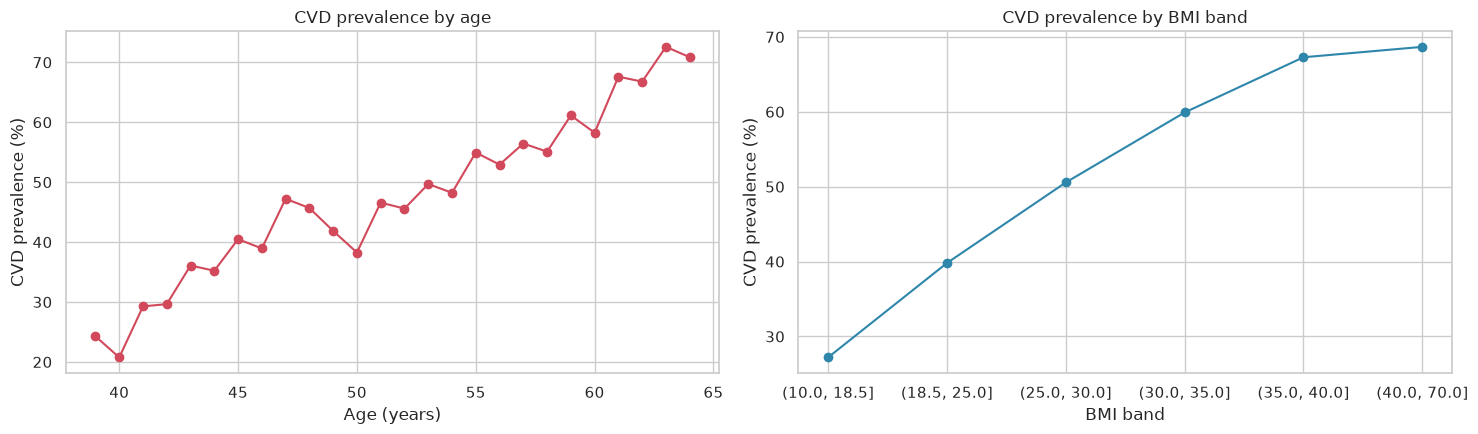

In [19]:
age_rate = clean_df.assign(age_int=clean_df.age_years.astype(int)).groupby("age_int")[TARGET].agg(["mean", "size"])
age_rate = age_rate[age_rate["size"] >= 100]
bmi_rate = clean_df.assign(bmi_band=pd.cut(clean_df.bmi, [10, 18.5, 25, 30, 35, 40, 70])).groupby("bmi_band", observed=True)[TARGET].mean()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].plot(age_rate.index, age_rate["mean"] * 100, marker="o", color="#d1495b")
axes[0].set(xlabel="Age (years)", ylabel="CVD prevalence (%)", title="CVD prevalence by age")
axes[1].plot(bmi_rate.index.astype(str), bmi_rate.values * 100, marker="o", color="#2e86ab")
axes[1].set(xlabel="BMI band", ylabel="CVD prevalence (%)", title="CVD prevalence by BMI band")
save("05_line_age_bmi")

**Prevalence tables.** The numbers behind the plots above and quoted in Task 6: CVD prevalence (%) and patient count by systolic BP band, age band and each categorical factor.

In [20]:
def prevalence(by):
    """CVD prevalence (%) and number of patients for each level of `by`."""
    t = clean_df.groupby(by, observed=True)[TARGET].agg(prevalence="mean", n="size")
    return t.assign(prevalence=(t.prevalence * 100).round(1))

sys_band = pd.cut(clean_df.ap_hi, [0, 120, 130, 140, 160, 300], right=False,
                  labels=["<120", "120-129", "130-139", "140-159", "160+"]).rename("systolic BP (mmHg)")
age_band = pd.cut(clean_df.age_years, [0, 40, 45, 50, 55, 60, 65],
                  labels=["<=40", "41-45", "46-50", "51-55", "56-60", "61-65"]).rename("age (years)")
for by in [sys_band, age_band, "cholesterol", "male", "active"]:
    print(prevalence(by).to_string(), end="\n\n")

                    prevalence      n
systolic BP (mmHg)                   
<120                      23.0  12709
120-129                   35.6  28202
130-139                   59.9   9213
140-159                   82.9  13987
160+                      86.1   4470

             prevalence      n
age (years)                   
<=40               23.4   2048
41-45              30.8   8039
46-50              42.5  11490
51-55              46.2  16432
56-60              56.2  18431
61-65              67.0  12141

             prevalence      n
cholesterol                   
1                  43.5  51421
2                  59.6   9295
3                  76.2   7865

      prevalence      n
male                   
0           49.2  44664
1           50.0  23917

        prevalence      n
active                   
0             53.3  13487
1             48.5  55094



### 4.5 Relationships: scatter plots


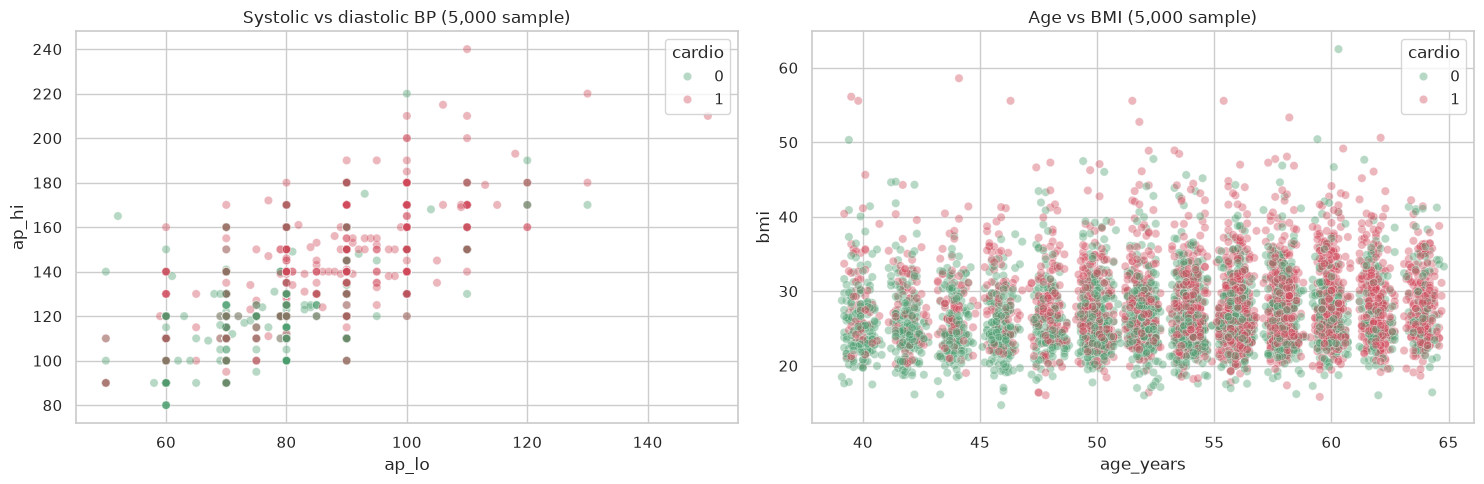

In [21]:
sample = clean_df.sample(5000, random_state=SEED)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=sample, x="ap_lo", y="ap_hi", hue=TARGET, alpha=0.4, ax=axes[0], palette=PALETTE)
axes[0].set_title("Systolic vs diastolic BP (5,000 sample)")
sns.scatterplot(data=sample, x="age_years", y="bmi", hue=TARGET, alpha=0.4, ax=axes[1], palette=PALETTE)
axes[1].set_title("Age vs BMI (5,000 sample)")
save("06_scatter")

### 4.6 Correlation matrix


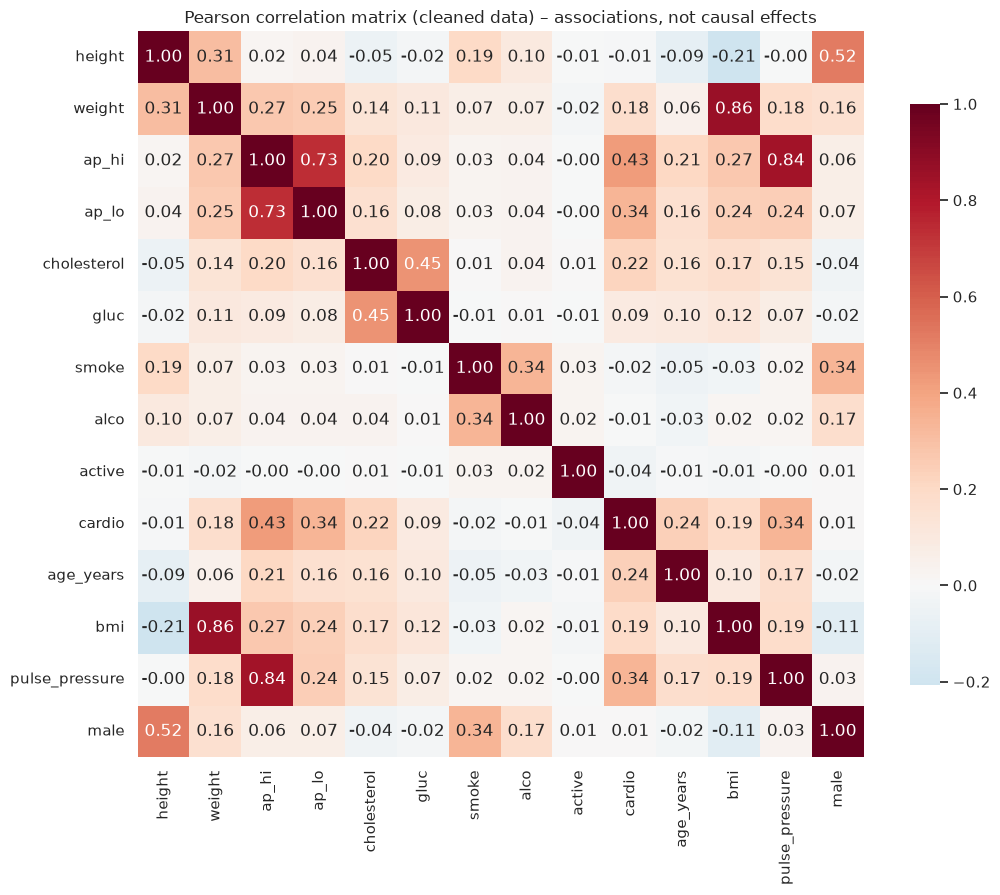

ap_hi             0.428
ap_lo             0.340
pulse_pressure    0.337
age_years         0.239
cholesterol       0.221
bmi               0.190
weight            0.180
gluc              0.090
active           -0.038
smoke            -0.016
height           -0.012
alco             -0.009
male              0.007
Name: cardio, dtype: float64

In [22]:
corr = clean_df.drop(columns="profile_id").corr(numeric_only=True)
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True, cbar_kws={"shrink": .8})
plt.title("Pearson correlation matrix (cleaned data) – associations, not causal effects")
save("07_correlation")
corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3)

### 4.7 Statistical tests of association (supporting RQ1–RQ3)


In [23]:
rows = []
n = len(clean_df)
for c in ["cholesterol", "gluc", "male", "smoke", "alco", "active"]:
    table = pd.crosstab(clean_df[c], clean_df[TARGET])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    rows.append({"feature": c, "test": "chi-square", "statistic": chi2, "p_value": p,
                 "effect size": np.sqrt(chi2 / (n * (min(table.shape) - 1))), "effect measure": "Cramér's V"})
pos, neg = clean_df[clean_df[TARGET] == 1], clean_df[clean_df[TARGET] == 0]
for c in ["age_years", "bmi", "ap_hi", "ap_lo", "pulse_pressure", "height", "weight"]:
    u, p = stats.mannwhitneyu(pos[c], neg[c])
    rows.append({"feature": c, "test": "Mann-Whitney U", "statistic": u, "p_value": p,
                 "effect size": 2 * u / (len(pos) * len(neg)) - 1, "effect measure": "rank-biserial r"})
tests = pd.DataFrame(rows)
tests["significant (p<0.05)"] = tests.p_value < 0.05
tests.round(4)

,feature,test,statistic,p_value,effect size,effect measure,significant (p<0.05)
0,cholesterol,chi-square,3.362278e+03,0.0000,0.2214,Cramér's V,True
1,gluc,chi-square,5.796598e+02,0.0000,0.0919,Cramér's V,True
2,male,chi-square,3.457300e+00,0.0630,0.0071,Cramér's V,False
3,smoke,chi-square,1.824880e+01,0.0000,0.0163,Cramér's V,True
4,alco,chi-square,4.933700e+00,0.0263,0.0085,Cramér's V,True
5,active,chi-square,9.698010e+01,0.0000,0.0376,Cramér's V,True
6,age_years,Mann-Whitney U,7.479929e+08,0.0000,0.2724,rank-biserial r,True
7,bmi,Mann-Whitney U,7.216717e+08,0.0000,0.2276,rank-biserial r,True
8,ap_hi,Mann-Whitney U,8.832593e+08,0.0000,0.5025,rank-biserial r,True
9,ap_lo,Mann-Whitney U,8.121257e+08,0.0000,0.3815,rank-biserial r,True


## Task 5 – Machine Learning Models and Performance Evaluation

### 5a Model selection and justification
| Model | Why it was chosen |
|---|---|
| **Logistic Regression** | A baseline for binary classification. Its coefficients describe conditional model associations, not causal risk-factor effects; correlated derived predictors complicate interpretation. |
| **Random Forest** | An ensemble of decision trees that captures non-linear effects and interactions (for example age × blood pressure). It is robust to outliers and gives feature importances. |
| **Neural Network (MLP)** | A flexible non-linear model that suits a large dataset (~68k rows). It is the least interpretable of the three, which lets us test whether the extra complexity is worth it. |

A **dummy classifier** (always predicts the training prevalence) is included as a reference point that any useful model must beat.

SVM was not chosen because kernel SVM training scales roughly quadratically with the number of samples, which makes it impractical to tune with cross-validation on ~55k training rows.

### 5b Data splitting
An 80/20 **stratified, group-aware** train/test split (`StratifiedGroupKFold`). Records with an identical predictor profile share a group, so the same inputs can never appear in both the training and the test set. The test set is reserved for final evaluation after training-only model selection. Earlier repository experiments have already exposed test outcomes; this is an exploratory internal evaluation, not a pristine independent validation cohort. Tuning and robustness checks use **5-fold stratified group cross-validation** on the training set only.


In [24]:
# pulse_pressure is excluded: it equals ap_hi - ap_lo exactly, so it adds no information to the model.
FEATURES = ["age_years", "male", "height", "weight", "bmi", "ap_hi", "ap_lo",
            "cholesterol", "gluc", "smoke", "alco", "active"]
X, y, groups = clean_df[FEATURES], clean_df[TARGET], clean_df["profile_id"]

outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(outer.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train = groups.iloc[train_idx]

assert set(g_train).isdisjoint(groups.iloc[test_idx]), "a predictor profile leaked across train/test"
# Verify actual model-input identity cannot cross the split.
model_hash = pd.util.hash_pandas_object(X, index=False)
assert set(model_hash.iloc[train_idx]).isdisjoint(model_hash.iloc[test_idx])
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

print("Train:", X_train.shape, " Test:", X_test.shape, f" (test share {len(test_idx) / len(X):.1%})")
print("Train target balance:", round(y_train.mean(), 3), " Test:", round(y_test.mean(), 3))

# Log the model inputs (X) and the target (y)
print(f"\nFeatures X ({len(FEATURES)} columns):", ", ".join(FEATURES))
print(f"Target y: '{TARGET}' (1 = CVD present, 0 = no CVD)")
print("X shape:", X.shape, " y shape:", y.shape)
display(X.head())
display(y.value_counts().rename("count").to_frame()
         .assign(share=lambda d: (d["count"] / d["count"].sum()).round(3))
         .rename_axis(TARGET))

Train: (54865, 12)  Test: (13716, 12)  (test share 20.0%)
Train target balance: 0.495  Test: 0.495

Features X (12 columns): age_years, male, height, weight, bmi, ap_hi, ap_lo, cholesterol, gluc, smoke, alco, active
Target y: 'cardio' (1 = CVD present, 0 = no CVD)
X shape: (68581, 12)  y shape: (68581,)


,age_years,male,height,weight,bmi,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active
0,50.4,1,168,62.0,21.97,110,80,1,1,0,0,1
1,55.4,0,156,85.0,34.93,140,90,3,1,0,0,1
2,51.6,0,165,64.0,23.51,130,70,3,1,0,0,0
3,48.2,1,169,82.0,28.71,150,100,1,1,0,0,1
4,47.8,0,156,56.0,23.01,100,60,1,1,0,0,0


,count,share
cardio,,
0,34649,0.505
1,33932,0.495


### 5c Model training and hyperparameter tuning

Each model is tuned with 5-fold stratified group cross-validation on the training data only, scored by ROC-AUC.

**Selection rule (one-standard-error rule).** The final model is the *simplest* model, in the order Logistic Regression → Random Forest → MLP, whose cross-validated ROC-AUC is within one standard error of the best score. The standard error is the best candidate's fold standard deviation divided by √5. This reflects RQ5: a more complex, less interpretable model is chosen only if it is clearly better than a simpler one, not merely higher by noise.

**Methodological revisions.** Three choices changed during the project, and all are reported openly:
1. An earlier version picked the model with the highest *test-set* ROC-AUC. That lets the test set influence a modelling decision, which makes its scores optimistic. Selection now uses training cross-validation only, and the test set is used only to describe the chosen model.
2. In an earlier run, plain "highest CV score" selection picked the MLP over Random Forest by 0.00004 ROC-AUC, a gap far smaller than the fold-to-fold variation. The one-standard-error rule was adopted after this was observed, so it is a documented revision rather than a rule fixed before the analysis. In the current run Random Forest has the highest CV score itself, so both rules select it.
3. Pulse pressure was removed as a model input because it equals systolic minus diastolic BP exactly, and records with systolic equal to diastolic (pulse pressure of zero, 2 records) are now excluded as physiologically impossible. Pulse pressure is still used in the exploratory analysis.

**MLP early stopping.** The MLP stops training when the score on a random 10% of its training fold stops improving. That internal split is not group-aware, so it can slightly affect *when* training stops, but it never touches the cross-validation validation folds or the test set, so the evaluation keeps the group split.

In [25]:
# scikit-learn 1.8 deprecated `penalty`; l1_ratio=0 is L2 and l1_ratio=1 is L1.
# Older versions still need `penalty`, so the grid follows the installed version.
SKLEARN_18 = tuple(int(v) for v in sklearn.__version__.split(".")[:2]) >= (1, 8)
lr_penalty_grid = {"clf__l1_ratio": [0.0, 1.0]} if SKLEARN_18 else {"clf__penalty": ["l2", "l1"]}

searches = {
    "Logistic Regression": GridSearchCV(
        Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(solver="liblinear", max_iter=2000, random_state=SEED))]),
        {"clf__C": [0.001, 0.01, 0.1, 1, 10], **lr_penalty_grid},
        cv=cv, scoring="roc_auc", n_jobs=N_JOBS),
    "Random Forest": RandomizedSearchCV(
        RandomForestClassifier(random_state=SEED, n_jobs=1),
        {"n_estimators": [150, 300], "max_depth": [6, 8, 10, 12, None], "min_samples_leaf": [10, 20, 50, 100],
         "max_features": ["sqrt", 0.5]},
        n_iter=10, cv=cv, scoring="roc_auc", n_jobs=N_JOBS, random_state=SEED),
    # early_stopping holds out 10% of each training fold and stops when its score stops improving,
    # so fits converge instead of running to max_iter (the source of the ConvergenceWarnings).
    "Neural Network (MLP)": RandomizedSearchCV(
        Pipeline([("scaler", StandardScaler()), ("clf", MLPClassifier(max_iter=300, early_stopping=True, n_iter_no_change=10, random_state=SEED))]),
        {"clf__hidden_layer_sizes": [(32,), (64,), (64, 32), (128, 64)], "clf__alpha": [1e-4, 1e-3, 1e-2, 1e-1],
         "clf__learning_rate_init": [1e-3, 3e-3]},
        n_iter=10, cv=cv, scoring="roc_auc", n_jobs=N_JOBS, random_state=SEED),
}
best, best_params, selection_scores = {}, {}, {}
for name, s in searches.items():
    s.fit(X_train, y_train, groups=g_train)
    best[name], best_params[name] = s.best_estimator_, s.best_params_
    selection_scores[name] = float(s.best_score_)
    print(f"{name}: best CV ROC-AUC = {s.best_score_:.4f}\n   best params = {s.best_params_}")

mlp = best["Neural Network (MLP)"].named_steps["clf"]
print(f"Tuned MLP stopped after {mlp.n_iter_} of {mlp.max_iter} epochs")

# One-standard-error rule: simplest model within 1 SE of the best training-CV ROC-AUC
SIMPLICITY_ORDER = ["Logistic Regression", "Random Forest", "Neural Network (MLP)"]
top_name = max(selection_scores, key=selection_scores.get)
top_search = searches[top_name]
selection_se = float(top_search.cv_results_["std_test_score"][top_search.best_index_] / np.sqrt(cv.get_n_splits()))
selection_threshold = selection_scores[top_name] - selection_se
selected_name = next(n for n in SIMPLICITY_ORDER if selection_scores[n] >= selection_threshold)
print(f"Highest CV ROC-AUC: {top_name} ({selection_scores[top_name]:.5f}); one SE = {selection_se:.5f}")
print(f"Models within one SE (>= {selection_threshold:.5f}):", [n for n in SIMPLICITY_ORDER if selection_scores[n] >= selection_threshold])
print("Selected using training CV only (simplest within one SE):", selected_name)

dummy = DummyClassifier(strategy="prior").fit(X_train, y_train)

Logistic Regression: best CV ROC-AUC = 0.7912
   best params = {'clf__C': 0.01, 'clf__l1_ratio': 1.0}


Random Forest: best CV ROC-AUC = 0.7990
   best params = {'n_estimators': 300, 'min_samples_leaf': 100, 'max_features': 0.5, 'max_depth': 8}


Neural Network (MLP): best CV ROC-AUC = 0.7985
   best params = {'clf__learning_rate_init': 0.001, 'clf__hidden_layer_sizes': (128, 64), 'clf__alpha': 0.1}
Tuned MLP stopped after 30 of 300 epochs
Highest CV ROC-AUC: Random Forest (0.79900); one SE = 0.00214
Models within one SE (>= 0.79686): ['Random Forest', 'Neural Network (MLP)']
Selected using training CV only (simplest within one SE): Random Forest


### Training-CV diagnostics for tuned models
These folds were also used to select hyperparameters. Re-scoring the chosen settings is a descriptive tuning diagnostic, **not nested CV or an unbiased independent robustness estimate**. Small fold variation alone does not prove absence of overfitting. The final test comparison is internal exploratory evidence; external validation remains necessary.


In [26]:
cv_scores = {}
for name, m in best.items():
    r = cross_validate(m, X_train, y_train, groups=g_train, cv=cv, n_jobs=N_JOBS,
                       scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])
    cv_scores[name] = {k.replace("test_", ""): (v.mean(), v.std()) for k, v in r.items() if k.startswith("test_")}
pd.DataFrame({n: {k: f"{m:.4f} ± {s:.4f}" for k, (m, s) in d.items()} for n, d in cv_scores.items()}).T

,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.7271 ± 0.0037,0.7562 ± 0.0048,0.6620 ± 0.0047,0.7060 ± 0.0040,0.7912 ± 0.0042
Random Forest,0.7339 ± 0.0038,0.7556 ± 0.0026,0.6831 ± 0.0093,0.7175 ± 0.0055,0.7990 ± 0.0048
Neural Network (MLP),0.7338 ± 0.0048,0.7495 ± 0.0074,0.6941 ± 0.0097,0.7207 ± 0.0054,0.7985 ± 0.0058


### 5d Evaluation on the held-out partition
Model selection is already frozen using training CV. Test scores are descriptive comparisons, not a new model-selection criterion.


In [27]:
probas = {name: m.predict_proba(X_test)[:, 1] for name, m in best.items()}
results = {"Dummy (prior)": metrics(y_test, dummy.predict_proba(X_test)[:, 1])}
results.update({name: metrics(y_test, p) for name, p in probas.items()})
results_df = pd.DataFrame(results).T.round(4)
results_df

,Accuracy,Precision,Recall,F1,ROC-AUC,Avg precision,Brier
Dummy (prior),0.5052,0.0000,0.0000,0.0000,0.5000,0.4948,0.2500
Logistic Regression,0.7274,0.7591,0.6578,0.7048,0.7915,0.7709,0.1870
Random Forest,0.7337,0.7548,0.6839,0.7176,0.8038,0.7873,0.1794
Neural Network (MLP),0.7336,0.7523,0.6880,0.7188,0.8037,0.7844,0.1795


In [28]:
for name, m in best.items():
    print(f"=== {name} ===")
    print(classification_report(y_test, m.predict(X_test), target_names=["No CVD", "CVD"], digits=4))

=== Logistic Regression ===
              precision    recall  f1-score   support

      No CVD     0.7036    0.7955    0.7468      6930
         CVD     0.7591    0.6578    0.7048      6786

    accuracy                         0.7274     13716
   macro avg     0.7313    0.7267    0.7258     13716
weighted avg     0.7311    0.7274    0.7260     13716

=== Random Forest ===
              precision    recall  f1-score   support

      No CVD     0.7165    0.7824    0.7480      6930
         CVD     0.7548    0.6839    0.7176      6786

    accuracy                         0.7337     13716
   macro avg     0.7356    0.7332    0.7328     13716
weighted avg     0.7354    0.7337    0.7330     13716

=== Neural Network (MLP) ===


              precision    recall  f1-score   support

      No CVD     0.7181    0.7782    0.7470      6930
         CVD     0.7523    0.6880    0.7188      6786

    accuracy                         0.7336     13716
   macro avg     0.7352    0.7331    0.7329     13716
weighted avg     0.7350    0.7336    0.7330     13716



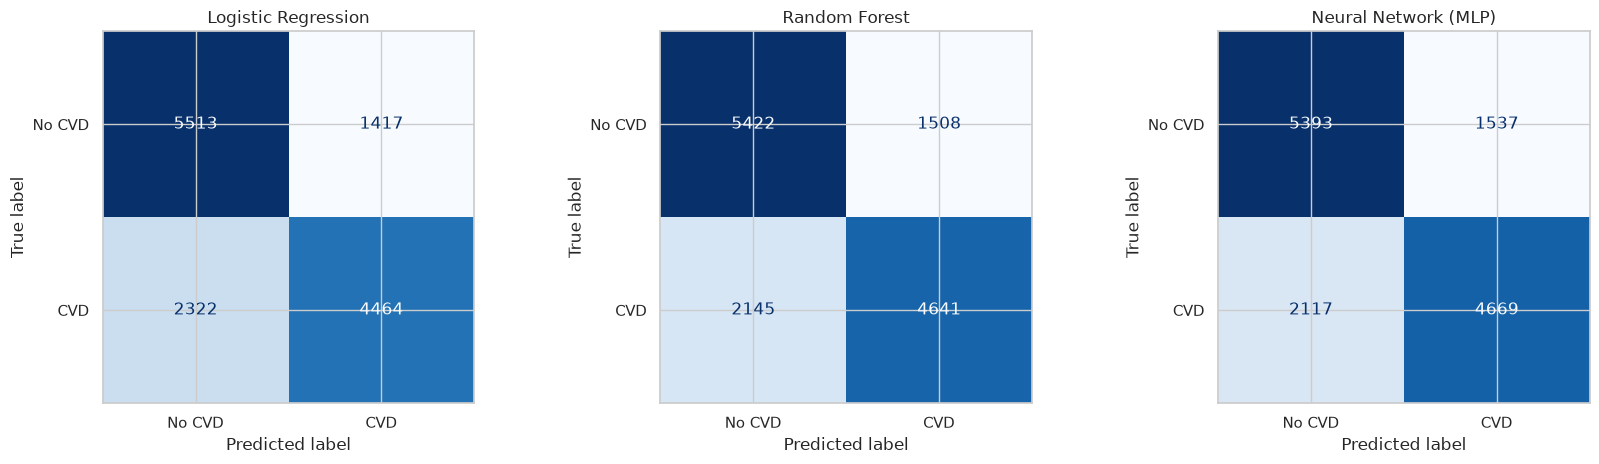

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (name, m) in zip(axes, best.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, display_labels=["No CVD", "CVD"], cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name)
save("08_confusion_matrices")

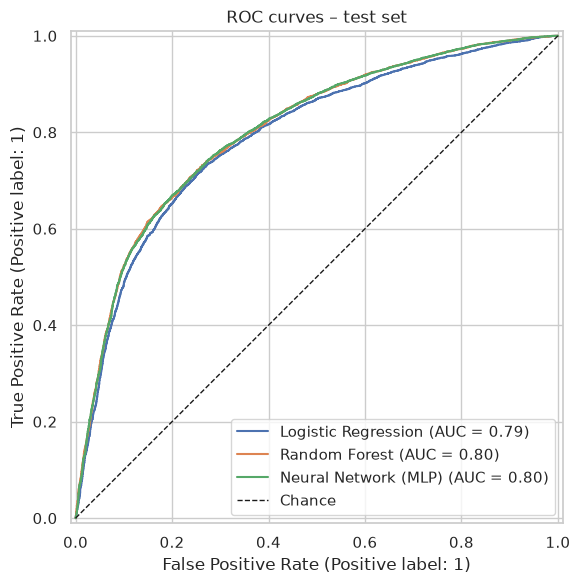

In [30]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, m in best.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
ax.set_title("ROC curves – test set"); ax.legend(loc="lower right")
save("09_roc_curves")

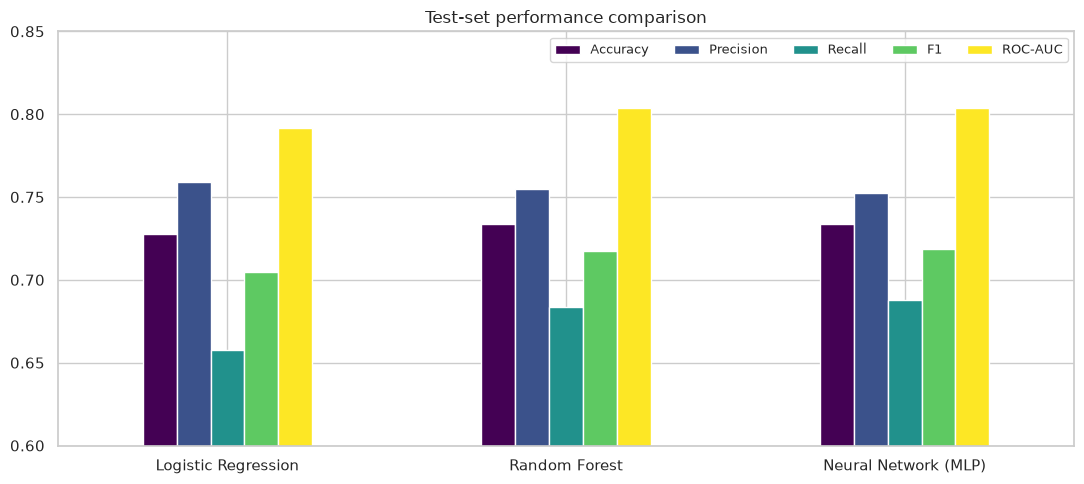

In [31]:
plot_df = results_df.drop(index="Dummy (prior)")[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]]
ax = plot_df.plot(kind="bar", figsize=(11, 5), ylim=(0.6, 0.85), colormap="viridis", rot=0)
ax.set_title("Test-set performance comparison"); ax.legend(loc="upper right", ncol=5, fontsize=9)
save("10_model_comparison")

### Feature importance (RQ1 / RQ4)
The coefficients, impurity importance and post-hoc test permutation analysis describe model behaviour. Test explanations must not drive subsequent feature selection on this split. Pulse pressure is excluded from the models because it is an exact function of systolic and diastolic BP. BMI still depends on height and weight, and systolic and diastolic BP are strongly correlated. Independent permutations can create implausible combinations and correlated predictors can mask each other's importance. Coefficients are penalised conditional associations, not independent clinical effects or intervention estimates. A future reduced-feature model must be developed on training data and assessed on fresh external data.


,coef (standardised),odds ratio per 1 SD
ap_hi,0.924,2.519
age_years,0.331,1.392
cholesterol,0.321,1.378
ap_lo,0.106,1.112
active,-0.084,0.920
weight,0.078,1.081
bmi,0.065,1.067
gluc,-0.046,0.955
alco,-0.041,0.960
smoke,-0.028,0.972


,Logistic Regression,Random Forest,Neural Network (MLP)
ap_hi,0.1693,0.1860,0.1820
age_years,0.0290,0.0391,0.0343
cholesterol,0.0223,0.0282,0.0318
ap_lo,0.0015,0.0025,0.0043
bmi,0.0009,0.0023,0.0010
active,0.0019,0.0015,0.0030
gluc,0.0005,0.0013,0.0029
weight,0.0012,0.0012,0.0068
smoke,0.0004,0.0002,0.0007
height,0.0000,0.0001,0.0008


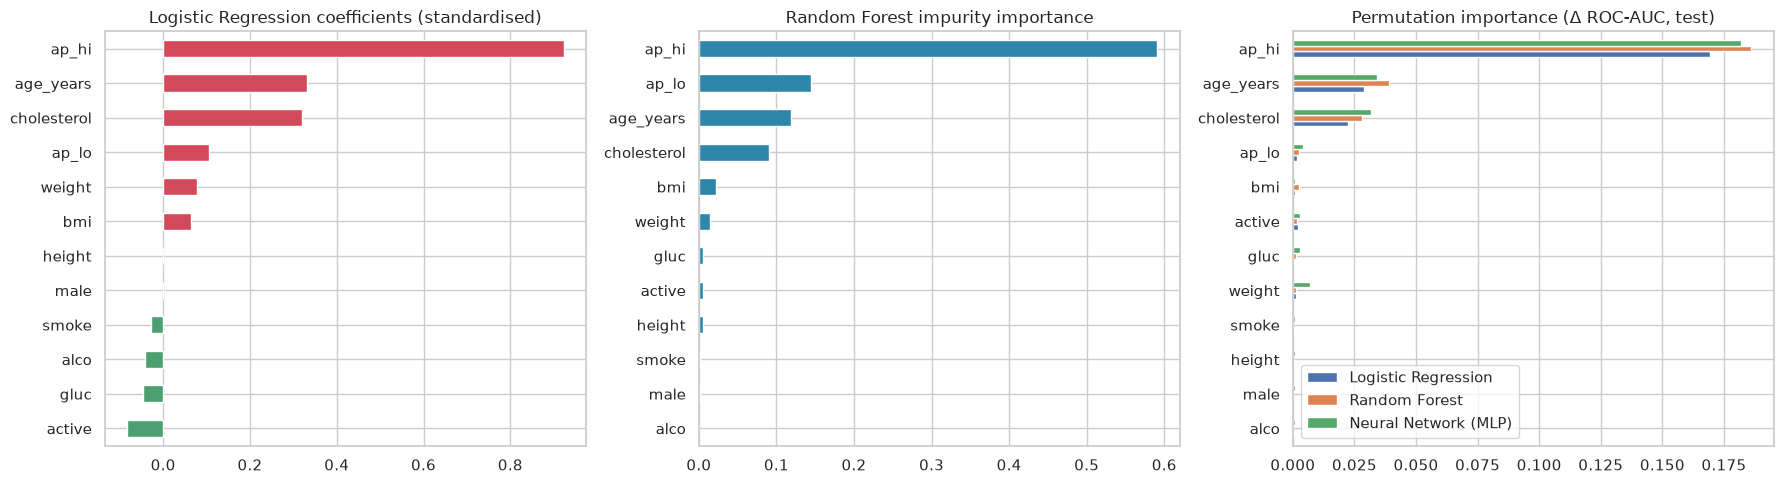

In [32]:
lr = best["Logistic Regression"].named_steps["clf"]
lr_coef = pd.DataFrame({"coef (standardised)": lr.coef_[0], "odds ratio per 1 SD": np.exp(lr.coef_[0])}, index=FEATURES)
lr_coef = lr_coef.reindex(lr_coef["coef (standardised)"].abs().sort_values(ascending=False).index).round(3)
rf_imp = pd.Series(best["Random Forest"].feature_importances_, index=FEATURES).sort_values(ascending=False)
perm = {name: permutation_importance(m, X_test, y_test, scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=N_JOBS).importances_mean
        for name, m in best.items()}
perm_df = pd.DataFrame(perm, index=FEATURES).sort_values("Random Forest", ascending=False).round(4)
display(lr_coef); display(perm_df)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
coef_sorted = lr_coef["coef (standardised)"].sort_values()
coef_sorted.plot.barh(ax=axes[0], color=np.where(coef_sorted > 0, "#d1495b", "#4c9f70"))
axes[0].set_title("Logistic Regression coefficients (standardised)")
rf_imp.sort_values().plot.barh(ax=axes[1], color="#2e86ab"); axes[1].set_title("Random Forest impurity importance")
perm_df.sort_values("Random Forest").plot.barh(ax=axes[2]); axes[2].set_title("Permutation importance (Δ ROC-AUC, test)")
save("11_feature_importance")

### 5e Model comparison and selection


In [33]:
model_rows = results_df.drop(index="Dummy (prior)")
best_name = selected_name  # frozen before test-set evaluation
print("Training-CV selection scores:", selection_scores)
print("Selected model (training CV):", best_name)
print(model_rows)
print("Test metrics do not change the selected model.")


Training-CV selection scores: {'Logistic Regression': 0.7912350419984531, 'Random Forest': 0.7989972401211446, 'Neural Network (MLP)': 0.7985195640777238}
Selected model (training CV): Random Forest
                      Accuracy  Precision  Recall      F1  ROC-AUC  Avg precision   Brier
Logistic Regression     0.7274     0.7591  0.6578  0.7048   0.7915         0.7709  0.1870
Random Forest           0.7337     0.7548  0.6839  0.7176   0.8038         0.7873  0.1794
Neural Network (MLP)    0.7336     0.7523  0.6880  0.7188   0.8037         0.7844  0.1795
Test metrics do not change the selected model.


### Save results
Everything needed to reproduce or cite the numbers in the report is written to one JSON file.


In [34]:
run_record = {
    "seed": SEED, "versions": VERSIONS, "plausibility_limits": LIMITS, "exclusions": exclusion_log,
    "split": {"method": "StratifiedGroupKFold (5 folds, first fold = test) grouped by predictor profile",
              "train": len(train_idx), "test": len(test_idx)},
    "selection_metric": "cross-validated ROC-AUC on training data", "threshold": 0.5,
    "selection_cv_scores": selection_scores,
    "selection_rule": "Simplest model (LR < RF < MLP) within one standard error of the best training-CV ROC-AUC; adopted as a documented revision after plain best-score selection picked the MLP by 0.00004 in an earlier run",
    "selection_one_se": selection_se, "selection_threshold": selection_threshold, "highest_cv_model": top_name,
    "mlp_epochs_used": int(best["Neural Network (MLP)"].named_steps["clf"].n_iter_),
    "evaluation_status": "Exploratory internal evaluation; earlier test results were inspected in repository history",
    "group_definition": "Hash of final engineered and rounded model inputs",
    "cv_diagnostic_limit": "Post-selection scores reuse tuning folds; not nested CV",
    "source_commit_before_review": "4d06ce7",
    "best_params": {k: {p: str(v) for p, v in d.items()} for k, d in best_params.items()},
    "cv_mean_std": cv_scores, "test": results, "selected_model": best_name,
}
path = REPORT_DIR / "notebook_results.json"
path.write_text(json.dumps(run_record, indent=2, default=float))
print("Saved", path.relative_to(ROOT))

Saved reports/notebook_results.json


### Uncertainty subgroup evaluation and probability diagnostics

Group-bootstrap intervals resample final-input profiles together and quantify uncertainty conditional on this fitted model and cohort. They do not measure uncertainty from training, cohort selection or transport to Nepal or India. Group differences are descriptive diagnostics, not proof of fairness or causation. Reliability plots complement Brier scores; precision-recall curves show the trade-off without choosing a test-optimised threshold.


,Accuracy,Recall,ROC-AUC
Logistic Regression,0.720 to 0.735,0.646 to 0.668,0.784 to 0.798
Random Forest,0.725 to 0.741,0.671 to 0.695,0.795 to 0.811
Neural Network (MLP),0.726 to 0.741,0.677 to 0.699,0.796 to 0.810


,N,Positive cases,Accuracy,Precision,Recall,F1,ROC-AUC,Avg precision,Brier
Group,,,,,,,,,
Recorded female,8972,4441,0.7323,0.7524,0.6843,0.7167,0.8039,0.7866,0.1796
Recorded male,4744,2345,0.7363,0.7592,0.6832,0.7192,0.8036,0.7893,0.1789
Age under 50,4150,1495,0.7993,0.7955,0.5960,0.6815,0.8326,0.7579,0.1483
Age 50 and above,9566,5291,0.7052,0.7457,0.7088,0.7267,0.7695,0.7910,0.1928


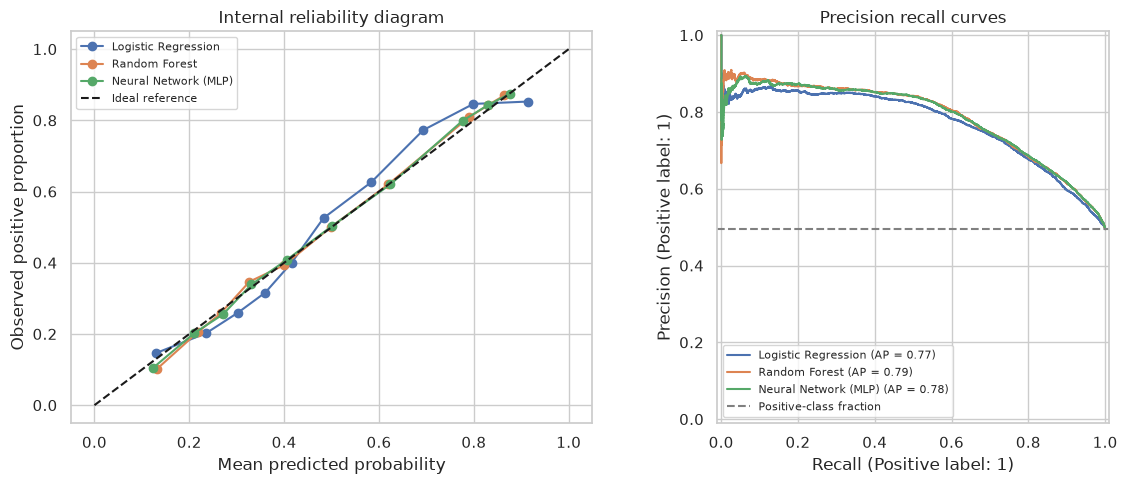

8374

In [35]:
# Diagnostic evaluation only: no test-driven feature, model or threshold selection.
from sklearn.calibration import calibration_curve
from sklearn.metrics import PrecisionRecallDisplay

def group_bootstrap_intervals(y_values, probabilities, group_values, repeats=300):
    """Percentile 95% intervals conditional on this cohort and fitted model."""
    y_values = np.asarray(y_values)
    probabilities = np.asarray(probabilities)
    group_codes, unique_groups = pd.factorize(np.asarray(group_values))
    rng = np.random.default_rng(SEED)
    estimates = []
    pred = probabilities >= 0.5
    for _ in range(repeats):
        drawn = rng.integers(0, len(unique_groups), len(unique_groups))
        weights = np.bincount(drawn, minlength=len(unique_groups))[group_codes]
        if weights[y_values == 1].sum() == 0 or weights[y_values == 0].sum() == 0:
            continue
        estimates.append([
            np.average(pred == y_values, weights=weights),
            recall_score(y_values, pred, sample_weight=weights, zero_division=0),
            roc_auc_score(y_values, probabilities, sample_weight=weights),
        ])
    intervals = np.quantile(np.asarray(estimates), [0.025, 0.975], axis=0)
    return {metric: [float(intervals[0, i]), float(intervals[1, i])]
            for i, metric in enumerate(["Accuracy", "Recall", "ROC-AUC"])}

intervals = {name: group_bootstrap_intervals(y_test, probabilities, groups.iloc[test_idx])
             for name, probabilities in probas.items()}
display(pd.DataFrame({name: {metric: f"{low:.3f} to {high:.3f}" for metric, (low, high) in ci.items()}
                      for name, ci in intervals.items()}).T)

subgroup_rows = []
chosen_proba = probas[selected_name]
for label, mask in {
    "Recorded female": X_test.male.to_numpy() == 0,
    "Recorded male": X_test.male.to_numpy() == 1,
    "Age under 50": X_test.age_years.to_numpy() < 50,
    "Age 50 and above": X_test.age_years.to_numpy() >= 50,
}.items():
    subgroup_rows.append({"Group": label, "N": int(mask.sum()),
                          "Positive cases": int(y_test.iloc[np.flatnonzero(mask)].sum()),
                          **metrics(y_test.iloc[np.flatnonzero(mask)], chosen_proba[mask])})
subgroups = pd.DataFrame(subgroup_rows).set_index("Group")
display(subgroups.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, probabilities in probas.items():
    observed, predicted = calibration_curve(y_test, probabilities, n_bins=10, strategy="quantile")
    axes[0].plot(predicted, observed, marker="o", label=name)
    PrecisionRecallDisplay.from_predictions(y_test, probabilities, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", label="Ideal reference")
axes[0].set(xlabel="Mean predicted probability", ylabel="Observed positive proportion", title="Internal reliability diagram")
axes[0].legend(fontsize=8)
axes[1].axhline(y_test.mean(), linestyle="--", color="grey", label="Positive-class fraction")
axes[1].set_title("Precision recall curves")
axes[1].legend(fontsize=8)
save("12_probability_diagnostics")

run_record["descriptive_statistics"] = clean_df[["age_years", "height", "weight", "ap_hi", "ap_lo", "bmi"]].agg(["mean", "median", "var", "std", "min", "max"]).T.to_dict(orient="index")
run_record["group_bootstrap_95_ci"] = intervals
run_record["subgroups"] = subgroups.reset_index().to_dict(orient="records")
run_record["uncertainty_note"] = "300 group-bootstrap resamples of fixed-model test predictions; conditional internal uncertainty, not retraining or external validation"
(REPORT_DIR / "notebook_results.json").write_text(json.dumps(run_record, indent=2, default=float))


## Task 6 – Interpretation and Conclusion

All numbers below come from this run (seed 42). The table printed below this cell shows the same test metrics.

### Answers to the research questions

**RQ1 – Which factors are associated with CVD?** Systolic blood pressure is the strongest association. CVD prevalence rises from 23% below 120 mmHg to 86% at 160 mmHg and above (rank-biserial r = 0.50). It is followed by diastolic BP and pulse pressure, age, cholesterol (43.5% → 59.6% → 76.2% across its three levels), BMI/weight and glucose. All of these are significant at p < 0.001. These are associations in this filtered cohort, not causal effects.

**RQ2 – Demographics.** Age is strongly associated with CVD: prevalence rises from 24% at 40 or under to 67% at 61–65. In Logistic Regression, each standard deviation of age (about 6.8 years) multiplies the odds by about 1.39. Recorded gender is not significantly associated (49.2% vs 50.0%, χ² p = 0.06), and the L1 penalty removed it from the Logistic Regression model.

**RQ3 – Lifestyle.** Physical activity has a small negative association with CVD (53.3% prevalence when inactive vs 48.5% when active). Smoking and alcohol show tiny negative associations (Cramér's V < 0.02). Self-reporting, confounding (most recorded smokers are men) or reverse causation could explain this. These are hypotheses that this data cannot test, so the result should not be read as a protective effect.

**RQ4 – Predictive contribution.** All three models rank systolic BP first. Permuting it lowers Random Forest test ROC-AUC by 0.19, about five times more than age (0.039) or cholesterol (0.028). Lifestyle variables, gender and height each change ROC-AUC by under 0.002. Systolic and diastolic BP are correlated and share importance, so they must be read together. Pulse pressure is not a model input because it equals systolic minus diastolic BP exactly.

**RQ5 – Prediction and model choice.** All three tuned models clearly beat the dummy baseline (accuracy 0.505, ROC-AUC 0.500):

| Model | Test accuracy | Recall | F1 | ROC-AUC (95% group-bootstrap CI) | Brier |
|---|---|---|---|---|---|
| Logistic Regression | 0.727 | 0.658 | 0.705 | 0.792 (0.784–0.798) | 0.187 |
| **Random Forest (selected)** | **0.734** | 0.684 | 0.718 | **0.804 (0.795–0.811)** | **0.179** |
| Neural Network (MLP) | 0.734 | 0.688 | 0.719 | 0.804 (0.796–0.810) | 0.180 |

Random Forest and the MLP are essentially tied on training CV (ROC-AUC 0.7990 vs 0.7985, a gap well inside one standard error of 0.0021), and their test confidence intervals overlap almost completely. Random Forest has the highest CV score and is also the simpler, more interpretable of the two, so the one-standard-error rule selects **Random Forest**. Logistic Regression is about 0.01 ROC-AUC lower. It remains the most transparent option when explanation matters more than a small gain in discrimination.

### Implications
- Blood pressure, age and cholesterol carry nearly all the predictive signal. This agrees with established clinical risk factors, and supports blood pressure and cholesterol management as prevention priorities.
- Because the strongest predictors are routine, low-cost measurements, a model like this could support screening for follow-up. It cannot diagnose CVD.
- At the 0.5 threshold, Random Forest misses nearly one in three CVD cases (recall 0.684). A screening use would need a lower threshold, chosen on development data for a defined use case, not on this test set.
- Subgroup results show weaker discrimination at age 50 and above (ROC-AUC 0.770 vs 0.833 under 50) and lower recall under 50 (0.596). Performance is therefore not uniform across groups.

### Limitations
- The inclusion filters removed 2% of records. They are study filters, not proven impossibilities, and the results do not apply to excluded patients.
- Cholesterol and glucose are 3-level categories, and the lifestyle variables are binary self-reports.
- The population, collection process and CVD definition are undocumented. The data is cross-sectional, so associations are not causal and no future-event risk is estimated.
- Grouping prevents identical-input leakage but cannot prove patient independence. The test set was inspected in an earlier version of the analysis, so it is an internal, not pristine, evaluation.
- The one-standard-error rule was adopted after a tie was observed in an earlier run. It is reported as a revision for that reason.

### Future research
- Validate externally on an independent, documented cohort, ideally longitudinal and including the populations of interest.
- Add richer predictors (laboratory lipids including triglycerides, medication, family history, ECG).
- Compare alternative justified filtering policies, gradient-boosting models, calibration methods and use-case-specific thresholds, all chosen on development data.

### Conclusion
After transparent data-quality filtering and a leakage-safe group split, routine measurements classify recorded CVD with about 73% accuracy and ROC-AUC of about 0.80. Systolic blood pressure, age and cholesterol drive the predictions. A simpler model (Random Forest, or Logistic Regression where transparency is paramount) performs essentially as well as a neural network.

### Submission package
The brief requires three files: this notebook, the Word report (`NIT6160_Cardio_Project_Report.docx`) and the PowerPoint presentation (`NIT6160_Cardio_Project_Presentation.pptx`).

In [36]:
print("Selected by training CV:", best_name)
display(results_df)
print("Retained rows:", len(clean_df))
print("Selected-model test recall:", results[best_name]["Recall"])
print("These are internal research results, not validated clinical risk estimates.")


Selected by training CV: Random Forest


,Accuracy,Precision,Recall,F1,ROC-AUC,Avg precision,Brier
Dummy (prior),0.5052,0.0000,0.0000,0.0000,0.5000,0.4948,0.2500
Logistic Regression,0.7274,0.7591,0.6578,0.7048,0.7915,0.7709,0.1870
Random Forest,0.7337,0.7548,0.6839,0.7176,0.8038,0.7873,0.1794
Neural Network (MLP),0.7336,0.7523,0.6880,0.7188,0.8037,0.7844,0.1795


Retained rows: 68581
Selected-model test recall: 0.6839080459770115
These are internal research results, not validated clinical risk estimates.


## References and run notes

[1] S. Ulianova, Cardiovascular Disease dataset, Kaggle, 2019. https://www.kaggle.com/datasets/sulianova/cardiovascular-disease-dataset

[2] C. M. Bhatt et al., Effective heart disease prediction using machine learning techniques, Algorithms, 16(2), 88, 2023. https://doi.org/10.3390/a16020088

[3] A. Kahraman, Machine learning techniques for improved prediction of cardiovascular diseases using integrated healthcare data, Frontiers in Artificial Intelligence, 8, 1694450, 2025. https://doi.org/10.3389/frai.2025.1694450

[4] H. Sadr et al., Cardiovascular disease diagnosis: a holistic approach using the integration of machine learning and deep learning models, European Journal of Medical Research, 29, 455, 2024. https://doi.org/10.1186/s40001-024-02044-7

[5] F. Pedregosa et al., Scikit-learn: Machine learning in Python, Journal of Machine Learning Research, 12, 2825–2830, 2011.

The recorded run completed all code cells without warnings. The causes were fixed, not hidden: Logistic Regression uses `l1_ratio` instead of the `penalty` argument deprecated in scikit-learn 1.8 (the grid falls back to `penalty` on older versions), and the MLP uses early stopping on a 10% validation split of each training fold, so fits converge before the 300-epoch limit. Randomized search evaluates ten candidates per nonlinear model. All models run on the CPU; scikit-learn does not use a GPU. Results are exploratory internal evidence, not clinical validation.
